In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"
# os.environ["MKL_NUM_THREADS"] = "1"
# os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
# os.environ["NUMEXPR_NUM_THREADS"] = "1"

print("OMP:", os.environ["OMP_NUM_THREADS"])
print("OPENBLAS:", os.environ["OPENBLAS_NUM_THREADS"])
# print("MKL:", os.environ["MKL_NUM_THREADS"])

OMP: 4
OPENBLAS: 4


In [2]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter(action="ignore", category=FutureWarning)
    import os, math
    from pathlib import Path
    import scanpy as sc
    import numpy as np
    import seaborn as sns
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from tqdm import tqdm
    from scipy import stats
    from scipy.stats import pearsonr, spearmanr
    from scipy.sparse import issparse

pd.set_option("display.max_rows", 500)

In [4]:
%load_ext autoreload
%autoreload 1

%aimport s7_helpers
import s7_helpers

In [18]:
plt.rcParams["figure.dpi"] = 80

In [6]:
obs = pd.read_csv(
    ".././4_all_sen_scores_obs.csv",
    index_col=0,
)
obs.rename(columns={"sp_score": "sp", "sid_score": "sid"}, inplace=True)
print(obs.shape)
obs.sample(2)

(1253024, 15)


,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,sp,RecSID,sid,ds,fridman,cellage,senmayo
CCGTTCAAGCGATGAC-1-GSM6544085,GSE212721,GSM6544085,41.0,Skin,CD4T,41.0,CD4 T cells,1035.0,0.314829,SID3,0.819375,1.811872,0.108140,0.042870,0.057858
H0015_LV_TCCCATGAGGCTAGCA,Heart_Nuclei,H5,53.0,Heart_Nuclei,Ventricular Cardiomyocyte,51.0,Ventricular cardiomyocytes,1164.0,NaN,SID3,0.932817,-1.585615,0.012082,0.042404,0.000000


### General

In [7]:
# центрирование по медиане:
for raw_score_col in ["sp", "sid", "ds"]:
    new_col = f"{raw_score_col}_centered_median"
    # Валидные значения конкретного score
    valid = obs[raw_score_col].notna()
    # Создаём столбец целиком с NaN
    obs[new_col] = np.nan

    # Медиана считается только для клеток, у которых данный score существует
    median_by_group = (
        obs.loc[valid]
        .groupby(["Tissue_global", "cell_type", "GSM_id"], observed=True)[raw_score_col]
        .transform("median")
    )

    # Центрируем и записываем обратно по исходным индексам
    obs.loc[valid, new_col] = obs.loc[valid, raw_score_col] - median_by_group

In [8]:
obs.head(2)

,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,sp,RecSID,sid,ds,fridman,cellage,senmayo,sp_centered_median,sid_centered_median,ds_centered_median
AAACCTGAGGCCGAAT-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,Fibroblast,21.0,Fibroblasts,950.0,3.951097,SID3,0.773698,0.156639,0.222860,0.048563,0.124413,1.170299,0.475860,-0.666287
AAACCTGAGTTAAGTG-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,CD8T,21.0,CD8 T cells,1247.0,0.114196,SID3,0.607294,0.125290,0.096653,0.047017,0.039243,-0.033471,-0.119954,-0.800847


### raw score Means corr

sp


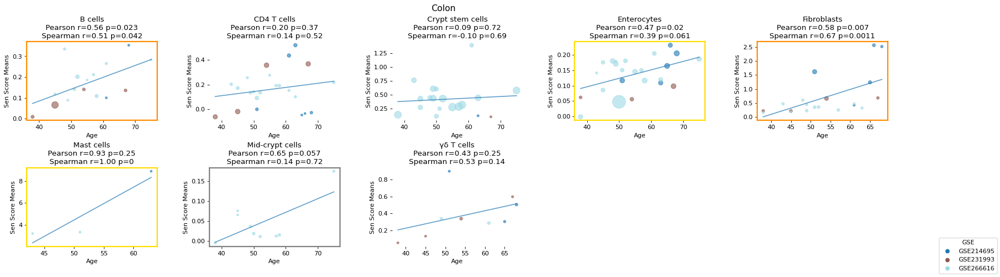

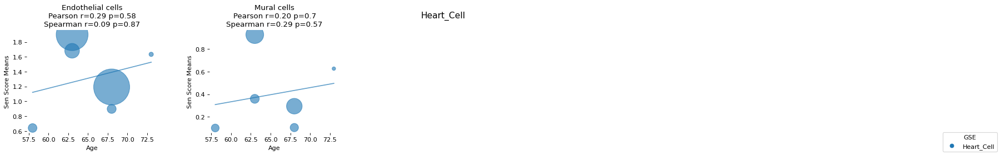

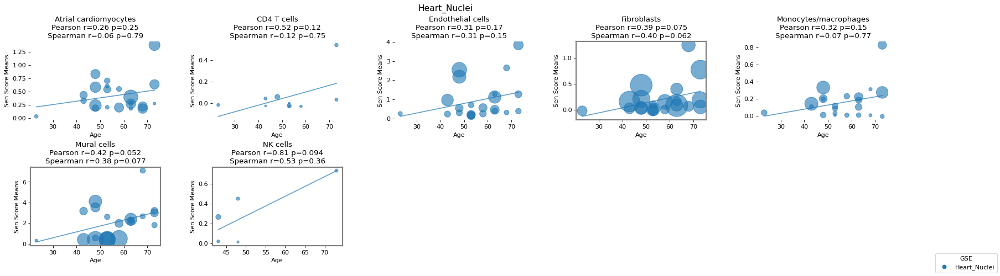

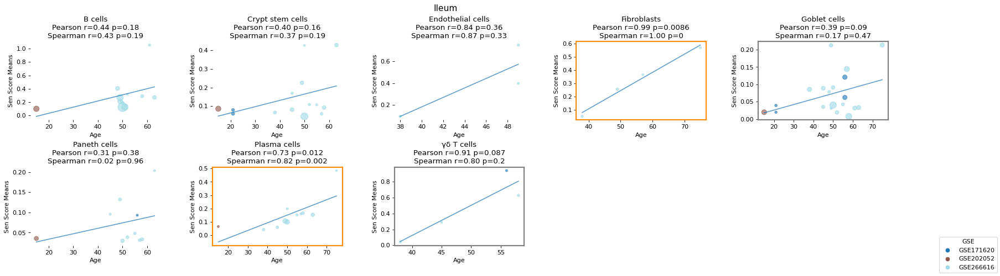

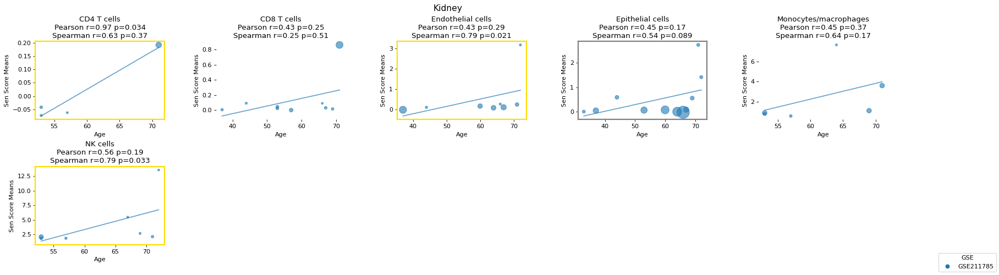

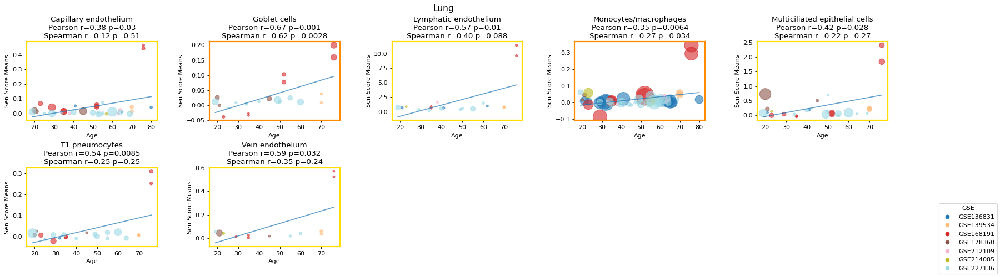

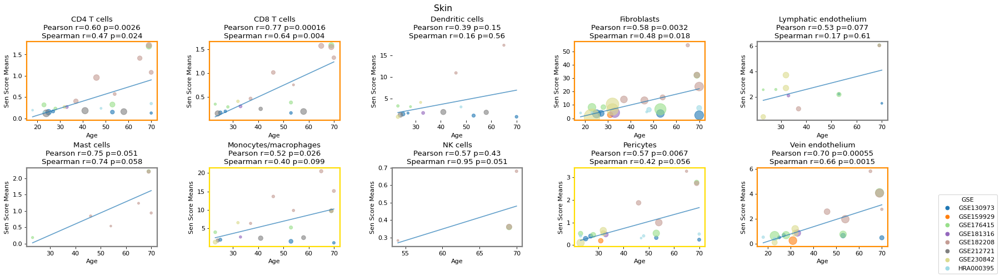

sid


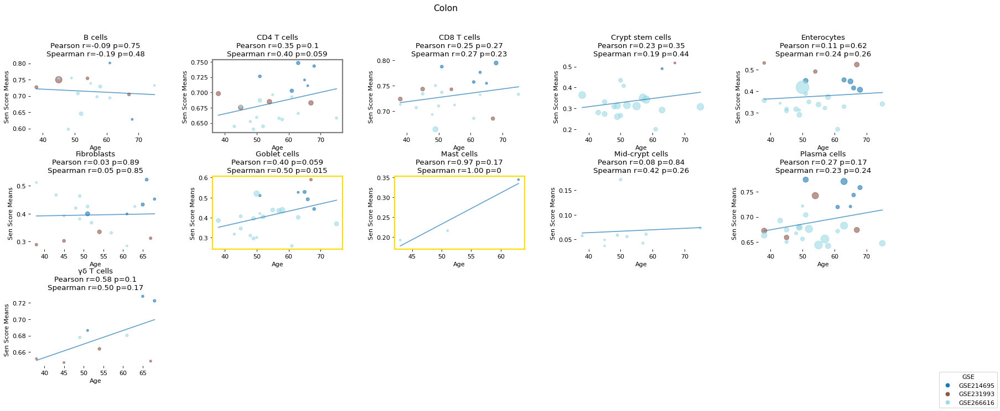

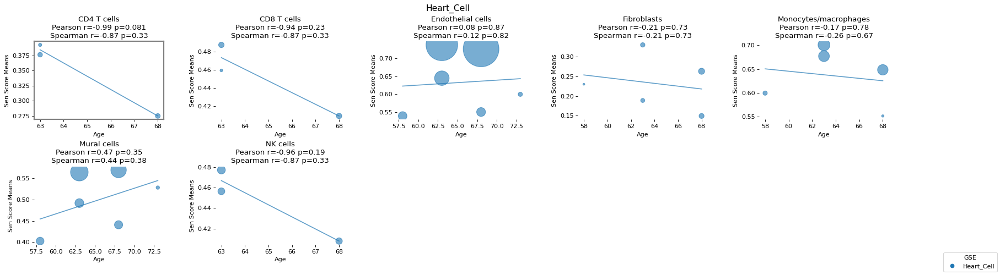

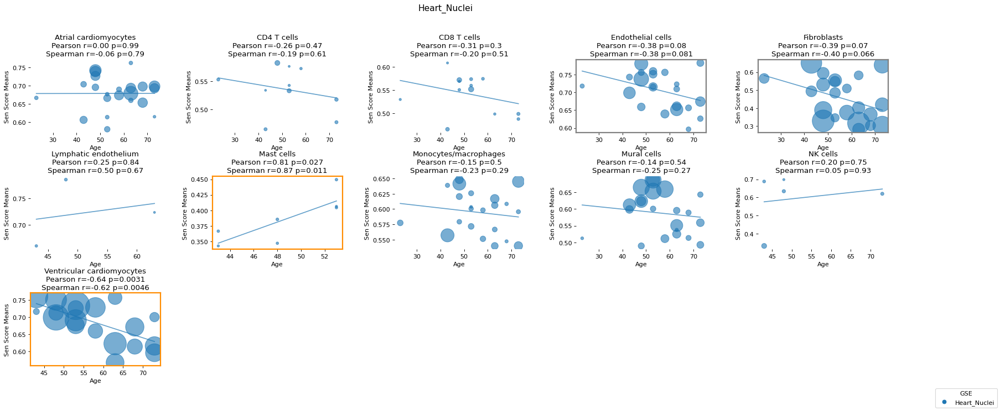

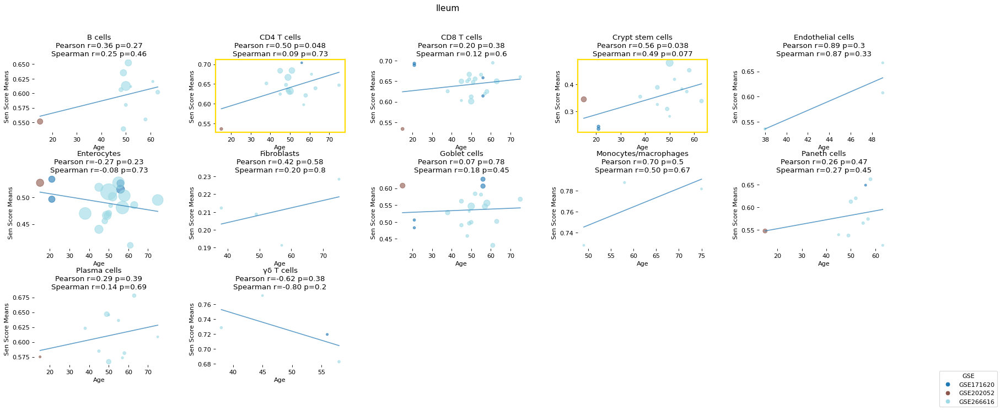

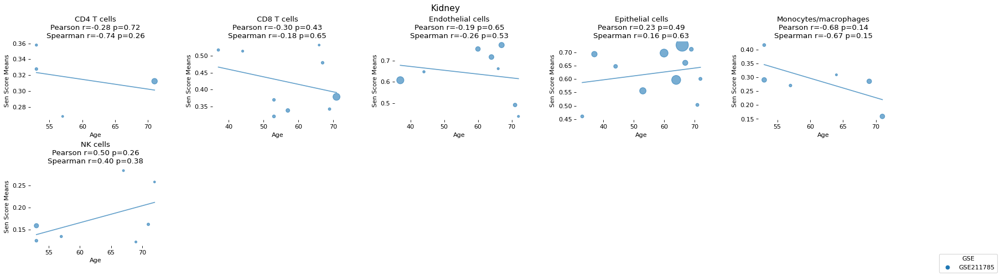

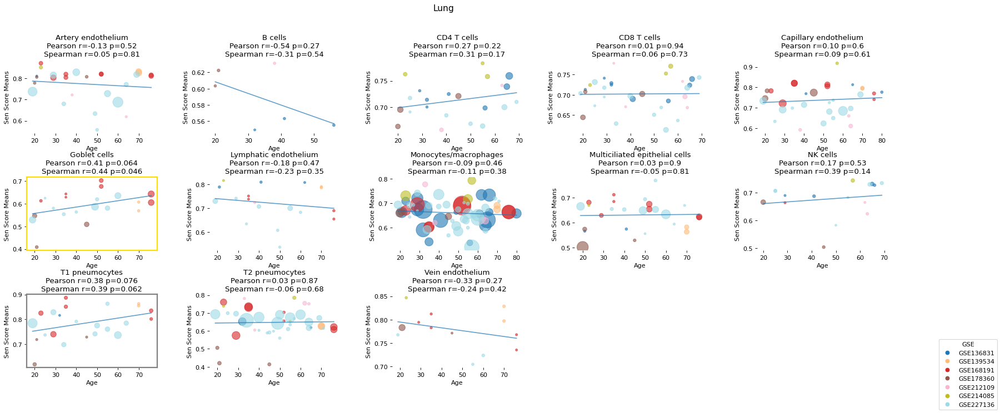

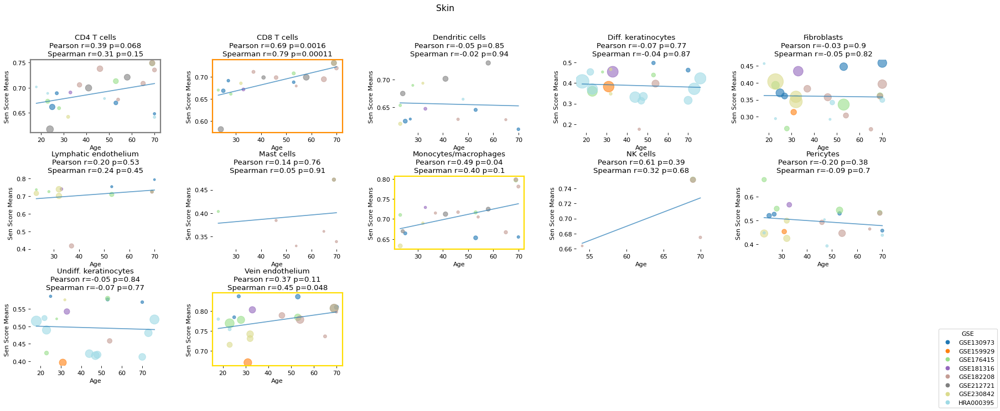

ds


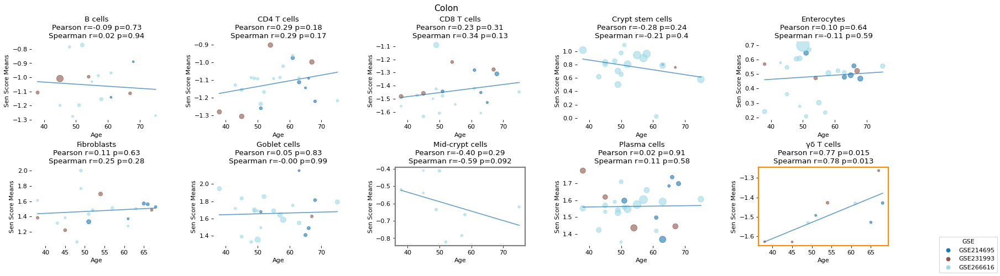

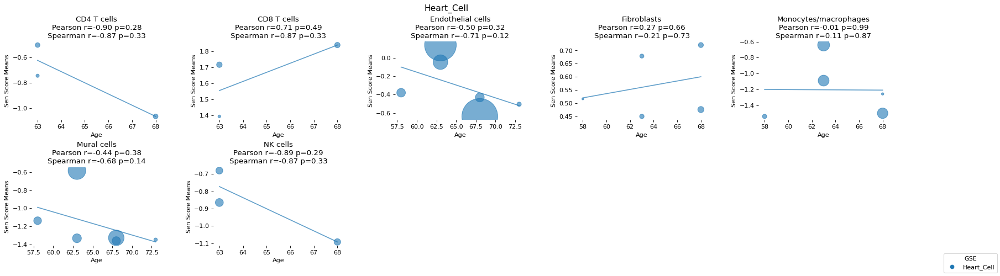

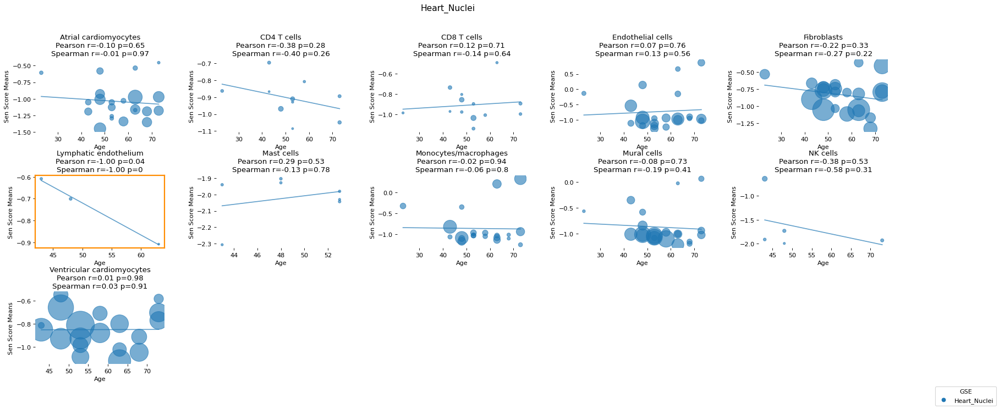

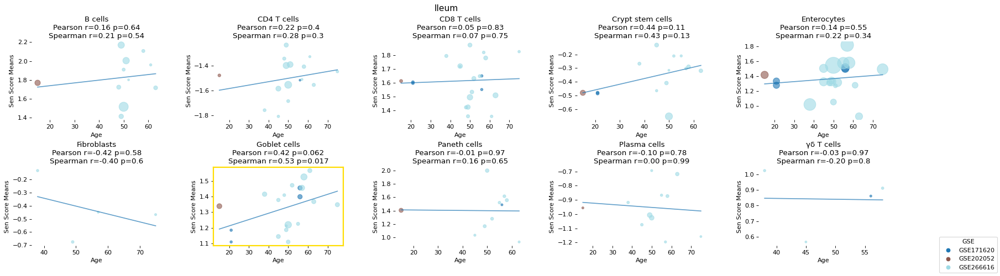

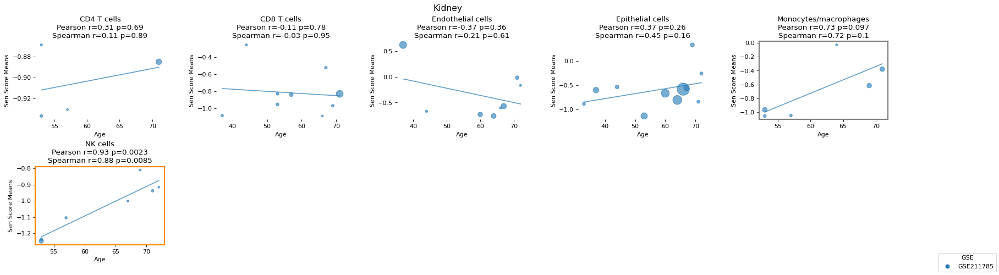

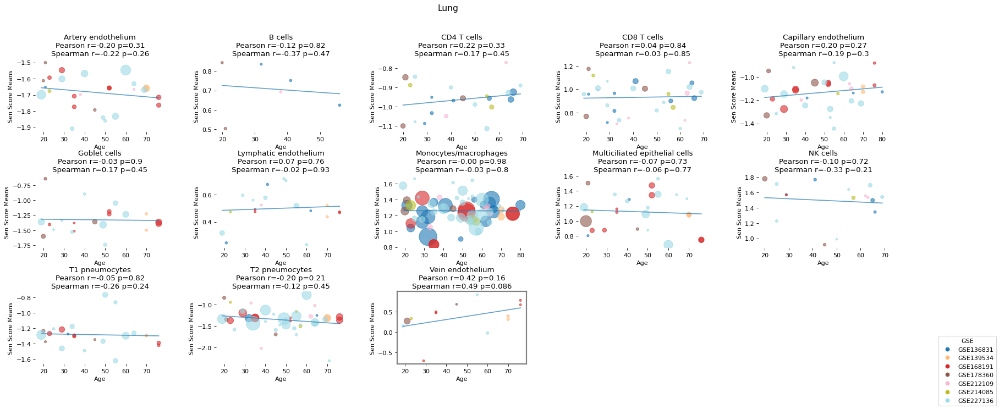

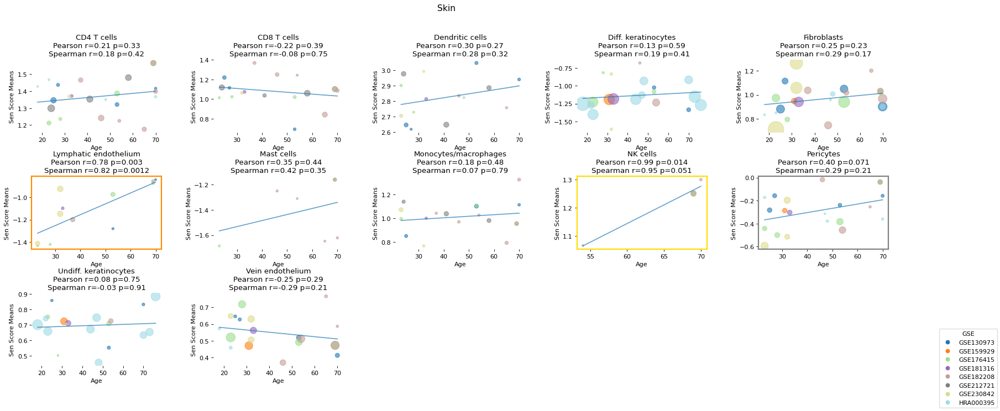

In [ ]:
"""
output saved to:
5.1_1_full_age_corrs
"""
# score_means_corr = []
# for raw_score_col in ["sp", "sid", "ds"]:
#     print(raw_score_col)
#     valid = obs[raw_score_col].notna()
#     obs_filt = obs.loc[valid]
#     stats_dict = s7_helpers.count_plot_sen_corrs(
#         obs_filt, raw_score_col, count_means_corr=True
#     )

#     df_stats = pd.DataFrame.from_dict(stats_dict, orient="index")
#     df_stats.index = pd.MultiIndex.from_tuples(
#         df_stats.index, names=["Tissue_global", "cell_type"]
#     )
#     df_stats["method"] = raw_score_col
#     df_stats = df_stats.reset_index()
#     score_means_corr.append(df_stats)

# score_means_corr = pd.concat(score_means_corr, ignore_index=True)

In [ ]:
"""done!"""
# score_means_corr.to_csv(
#     ".././5.1_1_raw_sen_scores_means_corr_stats.csv"
# )
# score_means_corr.sample(3)

,Tissue_global,cell_type,pearson_r,pearson_p,spearman_r,spearman_p,n_donors,pearson_fdr,spearman_fdr,method
20,Ileum,Fibroblasts,0.991367,0.008633,1.000000,0.000000,4,0.041441,0.000000,sp
143,Heart_Nuclei,Mast cells,0.286096,0.533939,-0.132288,0.777382,7,0.953278,0.957393,ds
49,Colon,CD4 T cells,0.348423,0.103246,0.399110,0.059216,23,0.495582,0.477759,sid


### Median centering

#### GMM, k=2

sp




Colon-B cells
[INFO] separability = 0.838
[INFO] KDE max = -0.011, thr = -0.072
run: p=40, sep=0.991, converged=True, n_iter=21
Adjusted threshold to 0.3311 to limit senescent fraction to 15.02%

threshold: 0.33107
Sen cells: 3420/3948 (15.02%)


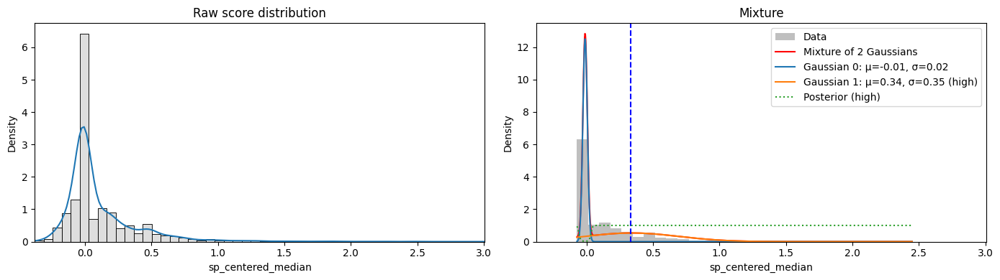



Colon-CD4 T cells
[INFO] separability = 0.750
[INFO] KDE max = -0.018, thr = -0.082
run: p=40, sep=1.399, converged=True, n_iter=16

threshold: 0.07500
Sen cells: 2187/6250 (34.99%)


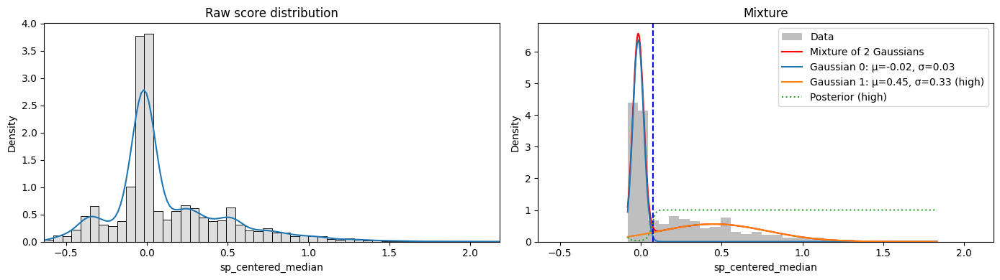



Colon-Crypt stem cells
[INFO] separability = 1.002
[INFO] KDE max = -0.017, thr = -0.141
run: p=40, sep=0.821, converged=True, n_iter=24
Adjusted threshold to 0.7798 to limit senescent fraction to 14.94%

threshold: 0.77980
Sen cells: 14784/15511 (14.94%)


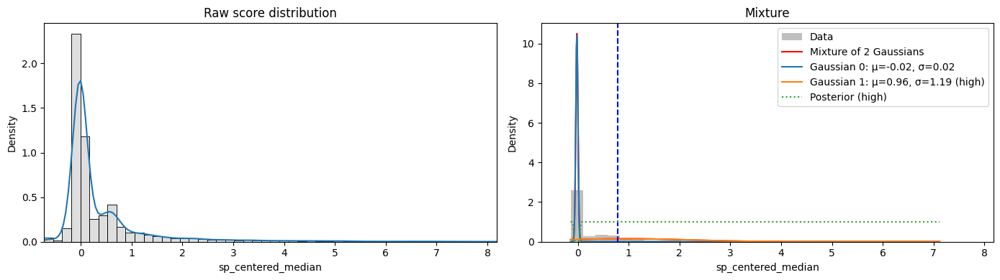



Colon-Enterocytes
[INFO] separability = 1.590
[INFO] KDE max = -0.014, thr = -0.061
run: p=40, sep=1.139, converged=True, n_iter=23

threshold: 0.04109
Sen cells: 5794/15294 (37.88%)


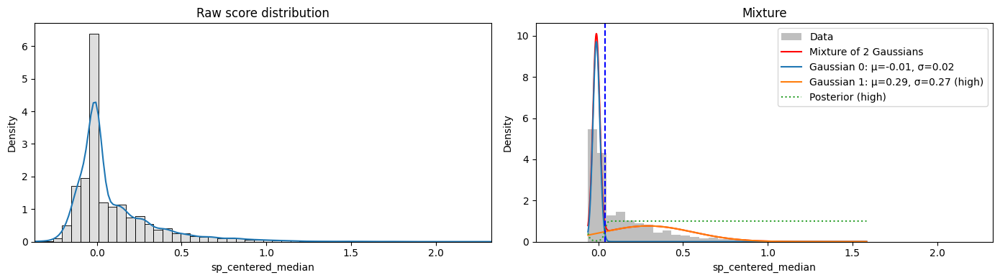



Colon-Fibroblasts
[INFO] separability = 0.435
[INFO] KDE max = -0.052, thr = -0.273
run: p=40, sep=1.194, converged=True, n_iter=14

threshold: 0.55780
Sen cells: 720/4262 (16.89%)


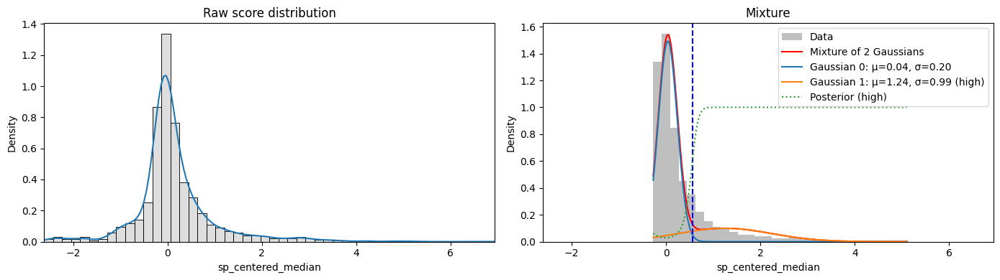



Colon-Mast cells
[INFO] separability = 0.581
[INFO] KDE max = -0.396, thr = -1.917
run: p=40, sep=1.297, converged=True, n_iter=14

threshold: 2.49915
Sen cells: 67/334 (20.06%)


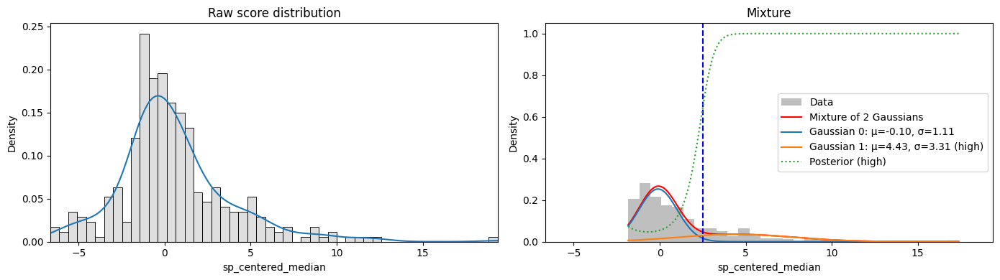



Colon-Mid-crypt cells
[INFO] separability = 0.990
[INFO] KDE max = -0.005, thr = -0.038
run: p=40, sep=1.227, converged=True, n_iter=9

threshold: 0.05143
Sen cells: 290/1458 (19.89%)


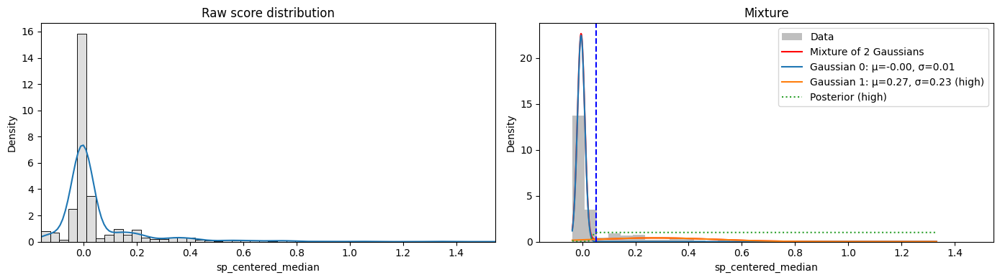



Colon-γδ T cells
[INFO] separability = 1.911
[INFO] KDE max = -0.040, thr = -0.210
run: p=40, sep=1.339, converged=True, n_iter=7

threshold: 0.64319
Sen cells: 82/1457 (5.63%)


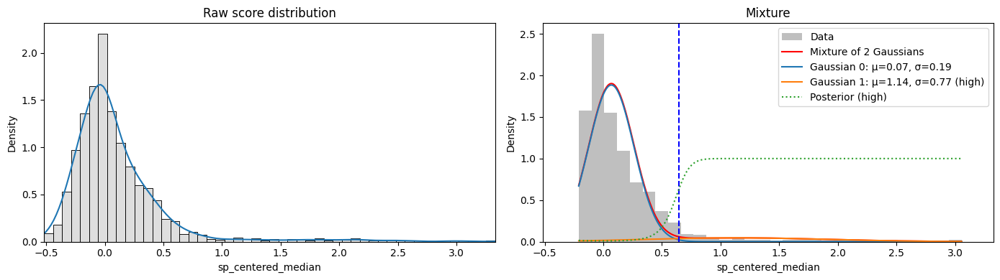

: 

: 

: 

In [7]:
# thr per ct
for raw_score_col in ["sp", "sid", "ds"]:
    print(raw_score_col)
    valid = obs[raw_score_col].notna()
    obs_filt = obs.loc[valid].copy()

    res_column = f"{raw_score_col}_is_sen_median_ct"
    obs[res_column] = pd.NA
    groups = obs_filt.groupby(["Tissue_global", "cell_type"], observed=True, sort=True)
    for (t, ct), df in groups:
        print(f"\n\n{t}-{ct}")
        thr = s7_helpers.binarization_wrap(
            df, score_col=f"{raw_score_col}_centered_median"
        )  # thr is float
        if thr is None:
            obs.loc[df.index, res_column] = pd.NA
        else:
            obs.loc[df.index, res_column] = df[f"{raw_score_col}_centered_median"] > thr

In [ ]:
# thr per gse
for raw_score_col in ["sp", "sid", "ds"]:
    print(raw_score_col)
    valid = obs[raw_score_col].notna()
    obs_filt = obs.loc[valid].copy()

    res_column = f"{raw_score_col}_is_sen_median_gse"
    obs[res_column] = pd.NA
    groups = obs_filt.groupby(
        ["Tissue_global", "cell_type", "GSE_id"], observed=True, sort=True
    )
    for (t, ct, gse), df in groups:
        print(f"\n\n{t}-{ct}-{gse}")
        thr = s7_helpers.binarization_wrap(
            df, score_col=f"{raw_score_col}_centered_median"
        )  # thr is float
        if thr is None:
            obs.loc[df.index, res_column] = pd.NA
        else:
            obs.loc[df.index, res_column] = df[f"{raw_score_col}_centered_median"] > thr

In [ ]:
# thr per donor
for raw_score_col in ["sp", "sid", "ds"]:
    print(raw_score_col)
    valid = obs[raw_score_col].notna()
    obs_filt = obs.loc[valid].copy()

    res_column = f"{raw_score_col}_is_sen_median_gsm"
    obs[res_column] = pd.NA
    groups = obs_filt.groupby(
        ["Tissue_global", "cell_type", "GSE_id", "GSM_id"], observed=True, sort=True
    )
    for (t, ct, gse, gsm), df in groups:
        print(f"\n\n{t}-{ct}-{gse}-{gsm}-{int(df.Age.iloc[0])} y.o.")
        thr = s7_helpers.binarization_wrap(
            df, score_col=f"{raw_score_col}_centered_median"
        )  # thr is float
        if thr is None:
            obs.loc[df.index, res_column] = pd.NA
        else:
            obs.loc[df.index, res_column] = df[f"{raw_score_col}_centered_median"] > thr

In [13]:
obs.sample(5)

,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,sp,RecSID,...,ds_centered_median,sp_is_sen_median_ct,sid_is_sen_median_ct,ds_is_sen_median_ct,sp_is_sen_median_gse,sid_is_sen_median_gse,ds_is_sen_median_gse,sp_is_sen_median_gsm,sid_is_sen_median_gsm,ds_is_sen_median_gsm
HCAHeart7664654_GTTACAGAGGGTCTCC-1,Heart_Nuclei,D3,58.0,Heart_Nuclei,Fibroblast,51.0,Fibroblasts,1090.0,-0.036000,SID3,...,0.481923,False,False,False,False,False,False,False,False,False
HCAHeart7836682_TCATTACCAAGCGTAG-1,Heart_Nuclei,D5,68.0,Heart_Nuclei,Fibroblast,61.0,Fibroblasts,533.0,-0.012000,SID3,...,0.480787,False,True,False,False,True,False,False,True,False
HCAHeartST10773168_HCAHeartST10781065_CGCTAATAGTAACCCG-1,Heart_Nuclei,AH1,48.0,Heart_Nuclei,Ventricular Cardiomyocyte,41.0,Ventricular cardiomyocytes,3119.0,NaN,SID3,...,0.390577,<NA>,False,False,<NA>,False,False,<NA>,False,False
HCAHeart7888927_CCAATCCGTTCTCATT-1,Heart_Nuclei,D6,68.0,Heart_Nuclei,Mural cell,61.0,Mural cells,688.0,4.972987,SID3,...,0.229002,False,False,False,False,False,False,False,False,False
CGGTTAACATTCCTGC-1-GSM4143263,GSE139534,GSM4143263,70.0,Lung,Macrophage,61.0,Monocytes/macrophages,3072.0,-0.036667,SID3,...,0.655372,False,False,False,False,False,False,False,False,False


In [15]:
obs.columns

Index(['GSE_id', 'GSM_id', 'Age', 'Tissue_global', 'cell_type_final',
       'Age_bin', 'cell_type', 'n_expr_genes', 'sp', 'RecSID', 'sid', 'ds',
       'fridman', 'cellage', 'senmayo', 'sp_centered_median',
       'sid_centered_median', 'ds_centered_median', 'sp_is_sen_median_ct',
       'sid_is_sen_median_ct', 'ds_is_sen_median_ct', 'sp_is_sen_median_gse',
       'sid_is_sen_median_gse', 'ds_is_sen_median_gse', 'sp_is_sen_median_gsm',
       'sid_is_sen_median_gsm', 'ds_is_sen_median_gsm'],
      dtype='object')

In [17]:
for col in obs.columns.sort_values():
    print(f"{col}: {obs[col].notna().sum()}")

Age: 1253024
Age_bin: 1253024
GSE_id: 1253024
GSM_id: 1253024
RecSID: 1253024
Tissue_global: 1253024


cell_type: 1253024
cell_type_final: 1253024
cellage: 1253024
ds: 1251121
ds_centered_median: 1251121
ds_is_sen_median_ct: 1251121
ds_is_sen_median_gse: 1251121
ds_is_sen_median_gsm: 1251121
fridman: 1253024
n_expr_genes: 1253024
senmayo: 1253024
sid: 1253024
sid_centered_median: 1253024
sid_is_sen_median_ct: 1253024
sid_is_sen_median_gse: 1253024
sid_is_sen_median_gsm: 1253024
sp: 783049
sp_centered_median: 783049
sp_is_sen_median_ct: 783049
sp_is_sen_median_gse: 783049
sp_is_sen_median_gsm: 783049


In [64]:
print(obs.shape)
obs.head()

(1253024, 27)


,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,sp,RecSID,...,ds_centered_median,sp_is_sen_median_ct,sid_is_sen_median_ct,ds_is_sen_median_ct,sp_is_sen_median_gse,sid_is_sen_median_gse,ds_is_sen_median_gse,sp_is_sen_median_gsm,sid_is_sen_median_gsm,ds_is_sen_median_gsm
AAACCTGAGGCCGAAT-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,Fibroblast,21.0,Fibroblasts,950.0,3.951097,SID3,...,-0.666287,False,True,False,False,True,False,False,True,False
AAACCTGAGTTAAGTG-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,CD8T,21.0,CD8 T cells,1247.0,0.114196,SID3,...,-0.800847,False,False,False,False,False,False,False,False,False
AAACCTGGTCTTCTCG-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,VE,21.0,Vein endothelium,724.0,0.151354,SID3,...,-0.132633,False,False,False,False,False,False,False,False,False
AAACCTGGTGCAACTT-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,DC,21.0,Dendritic cells,1888.0,1.127572,SID3,...,1.156324,False,False,False,False,False,False,False,False,False
AAACCTGTCAGCGACC-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,CD4T,21.0,CD4 T cells,721.0,0.178643,SID3,...,-1.520335,False,False,False,False,False,False,False,False,False


In [65]:
obs.to_csv(
    ".././5.1_obs_all_scores_and_bins.csv",
)

                                          sp_is_sen_median_ct 


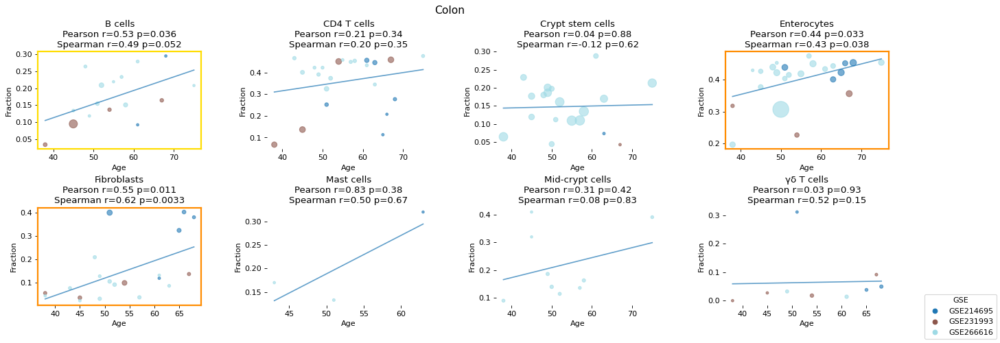

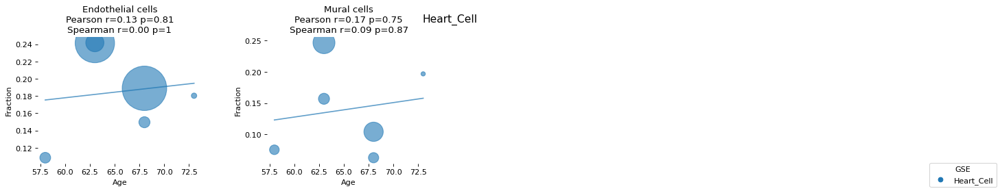

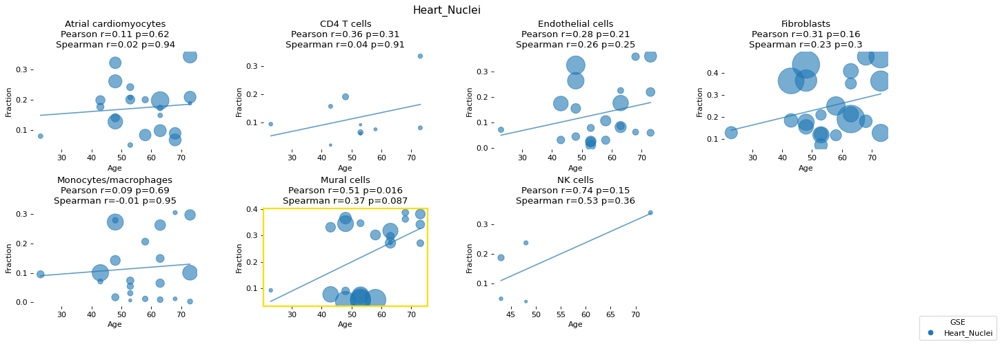

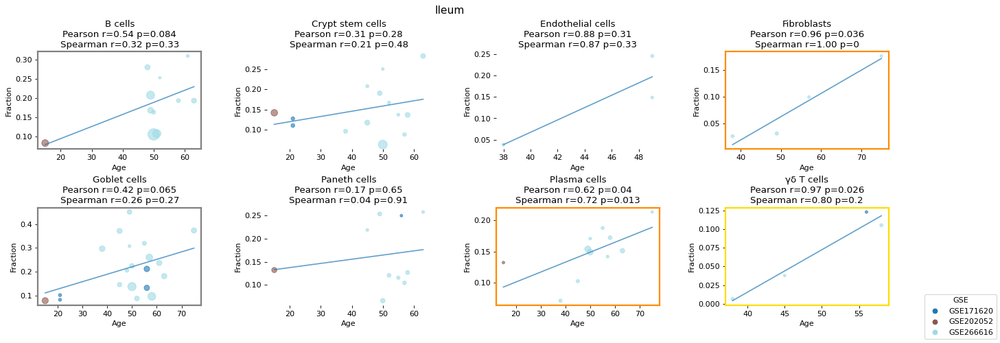

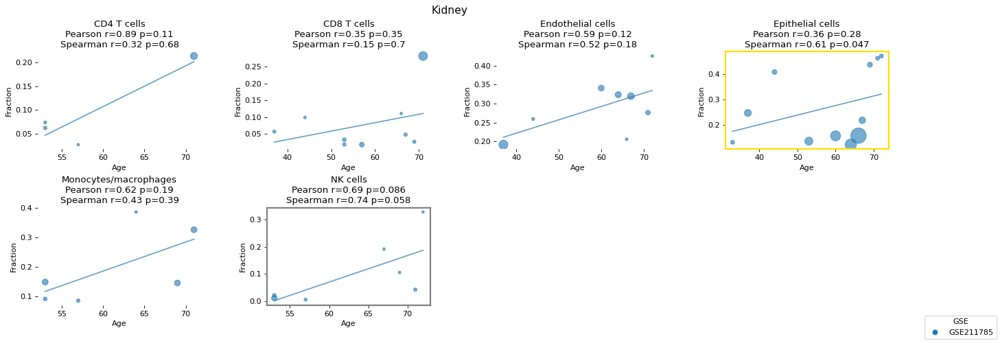

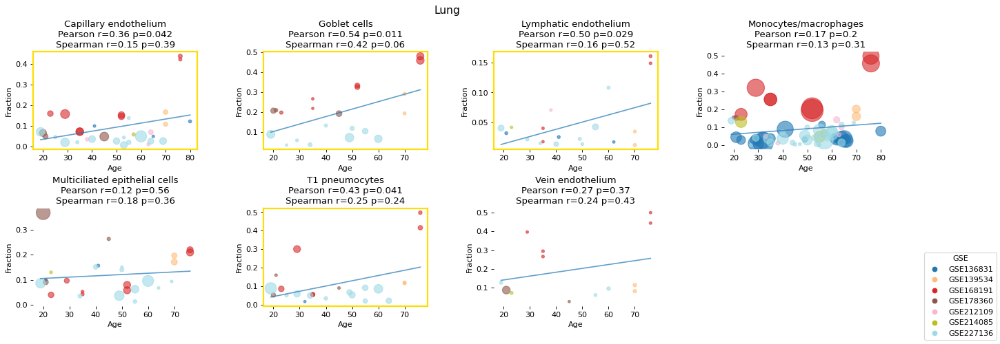

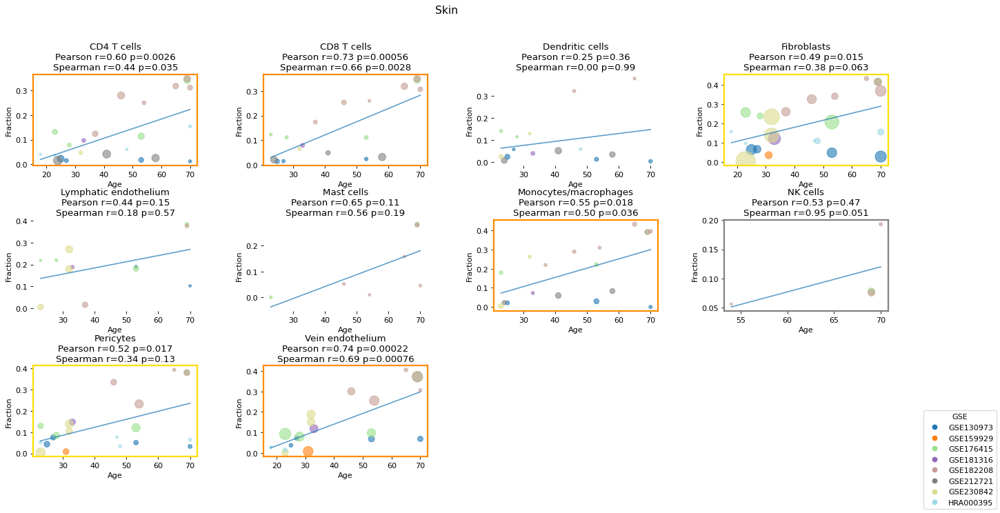

                                          sp_is_sen_median_gse 


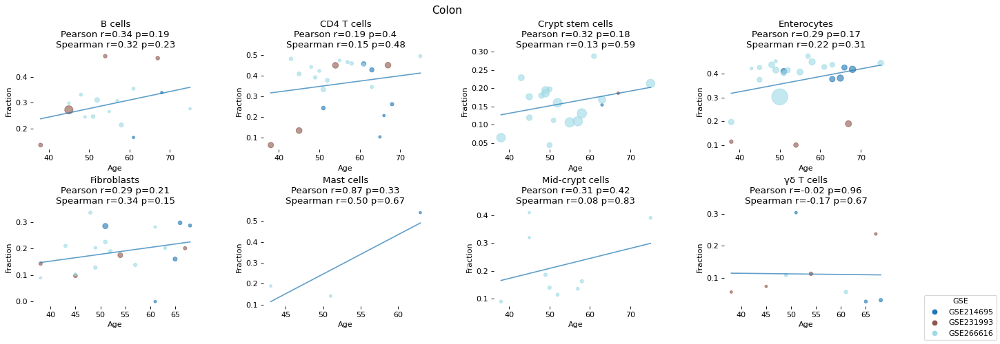

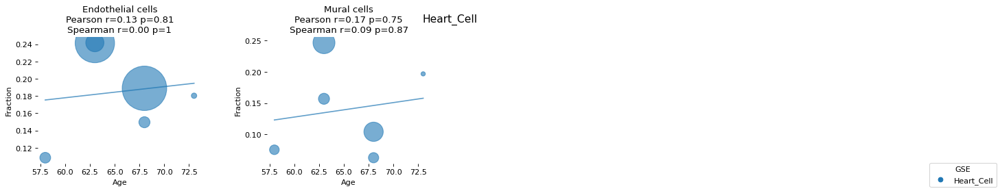

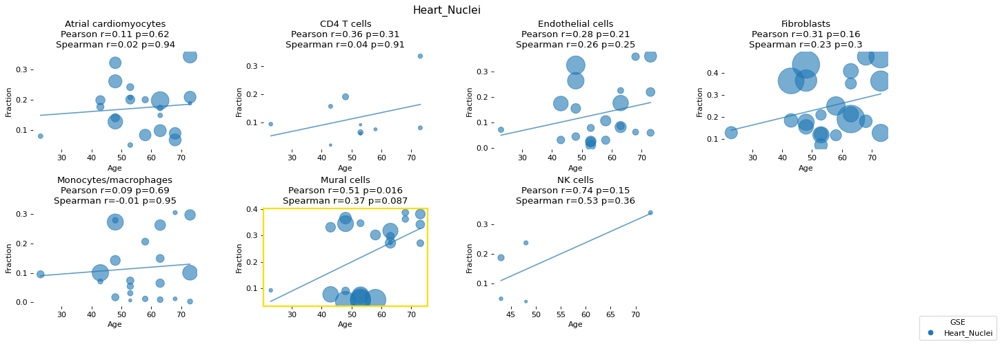

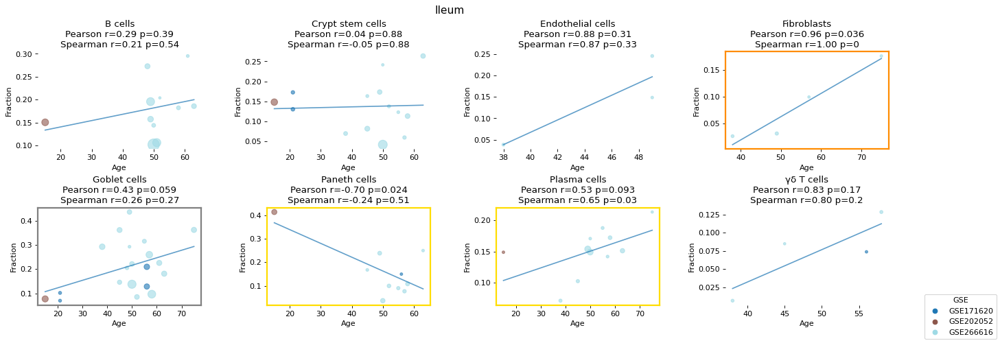

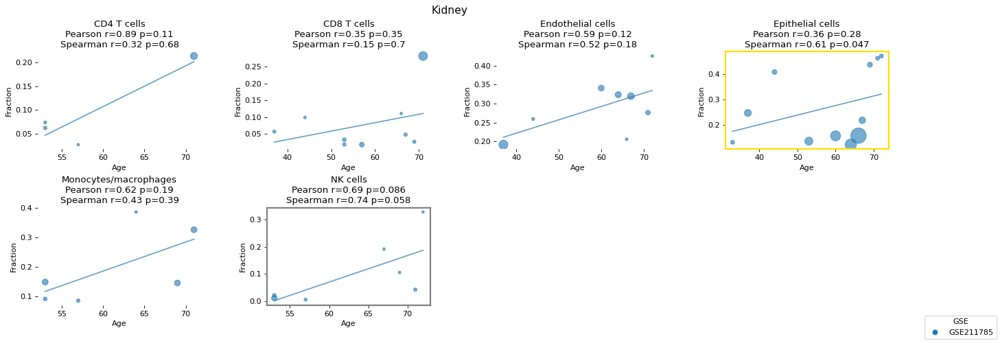

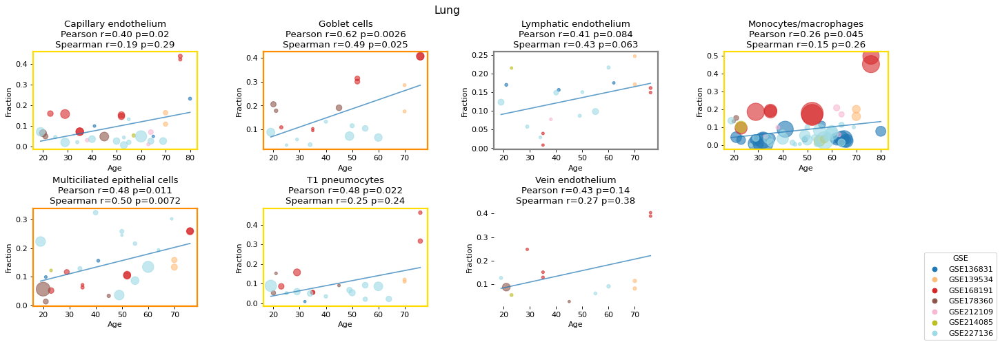

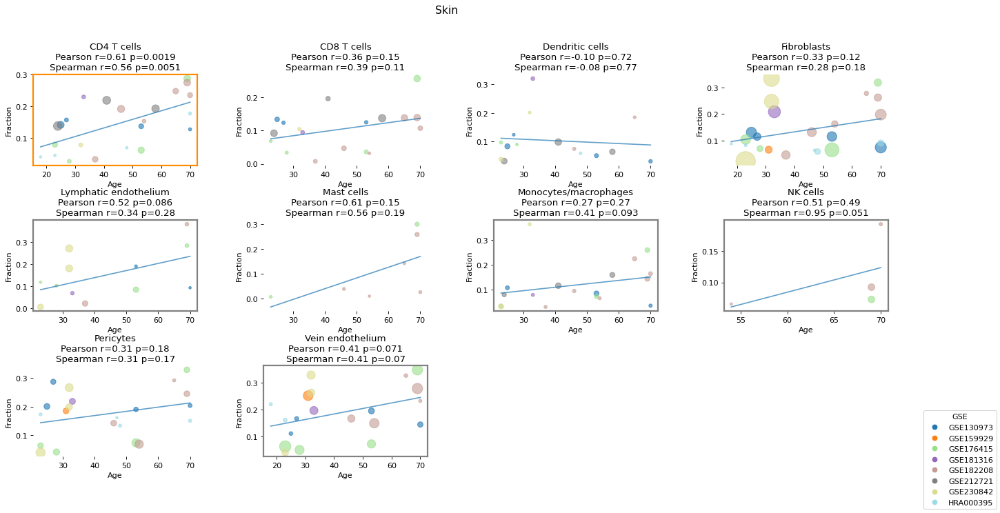

                                          sp_is_sen_median_gsm 


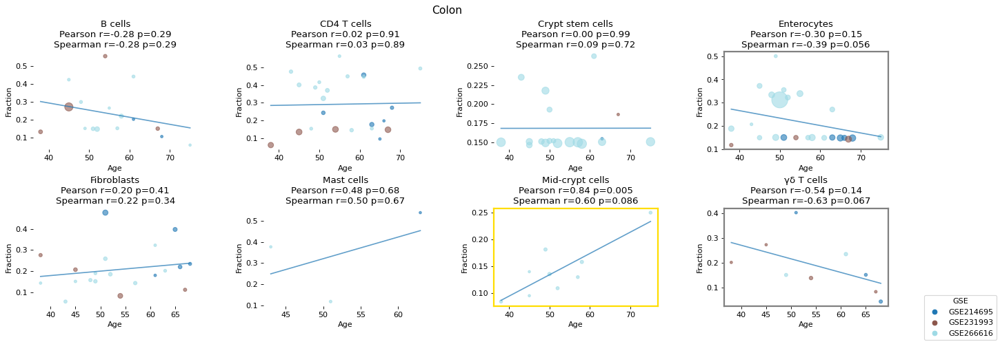

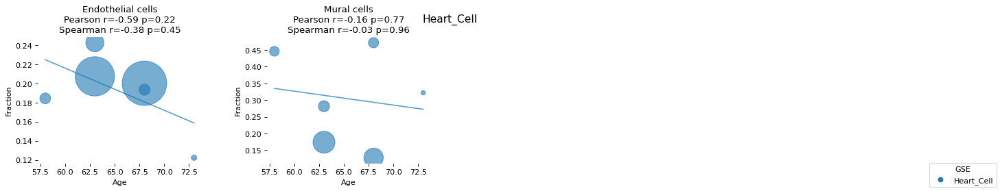

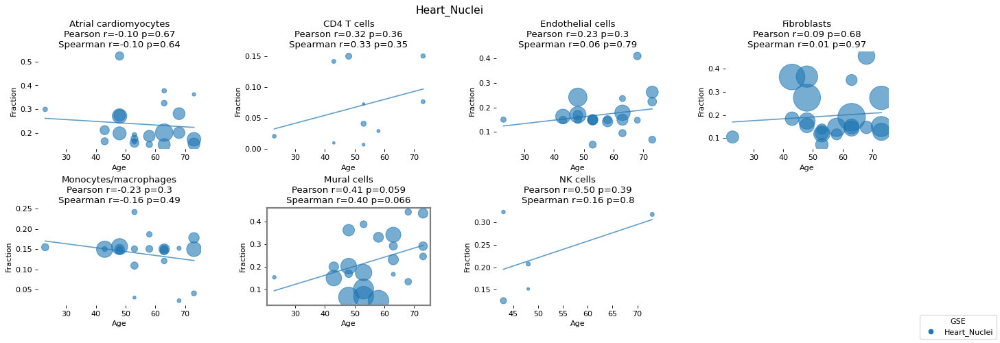

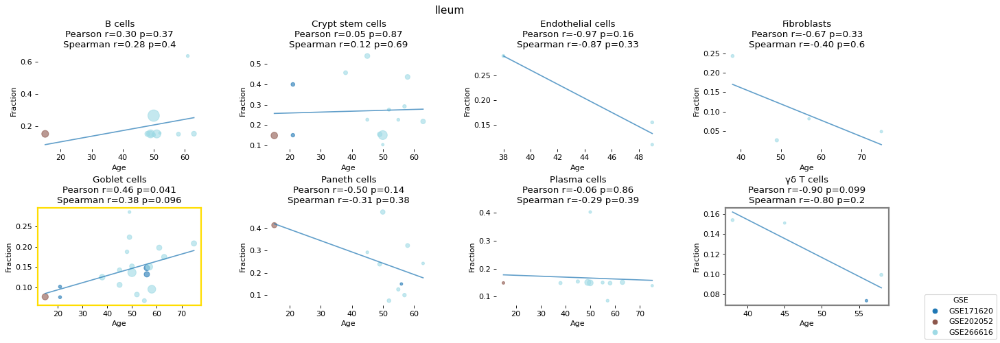

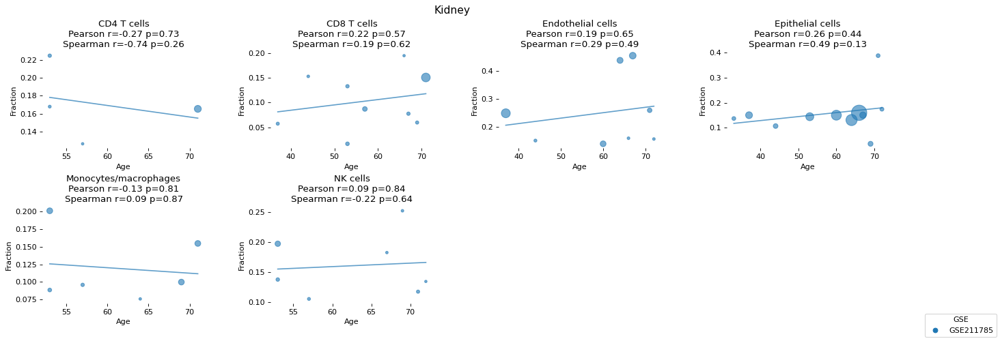

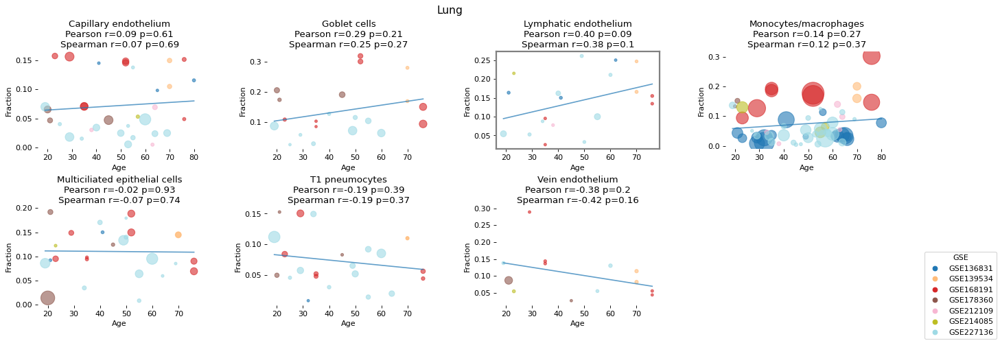

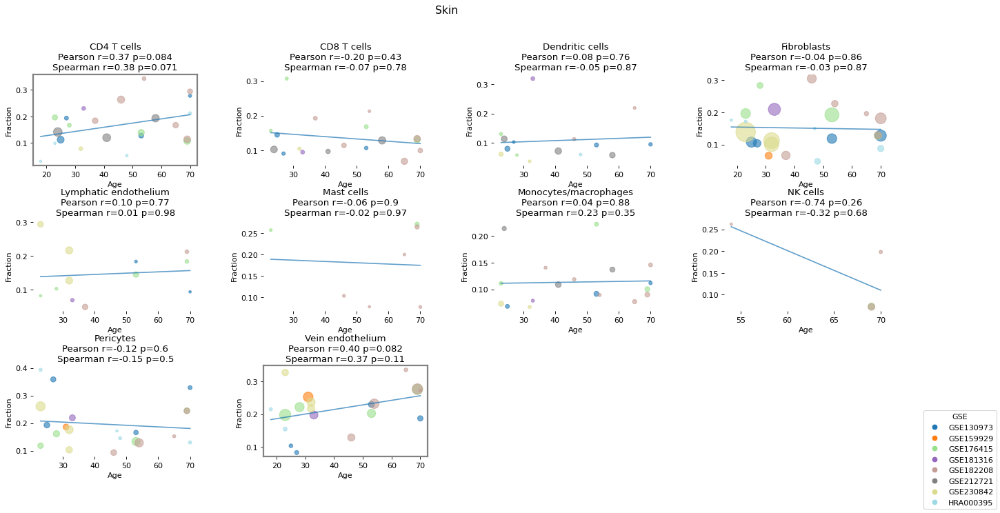

                                          sid_is_sen_median_ct 


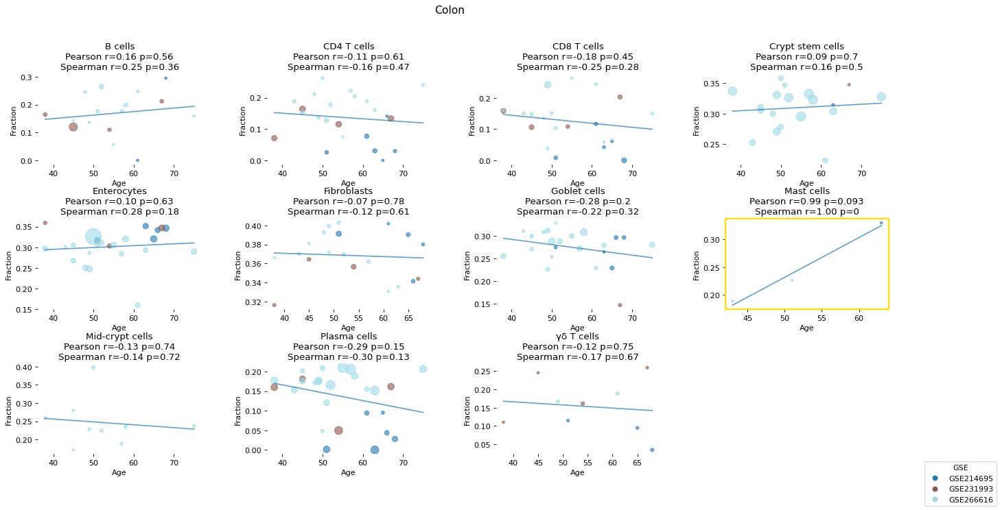

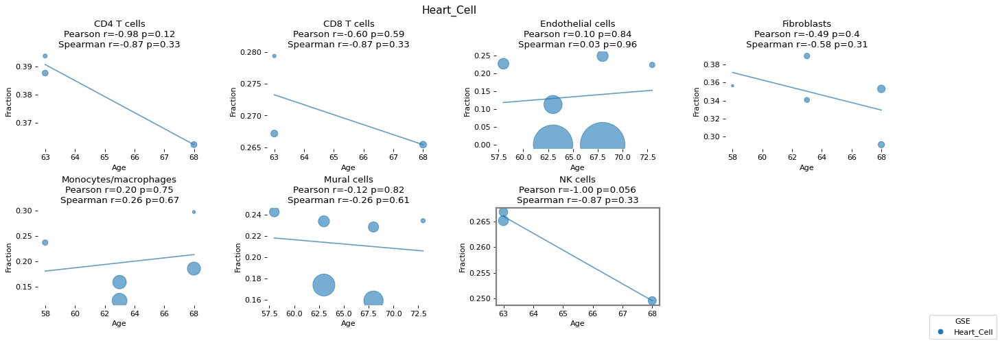

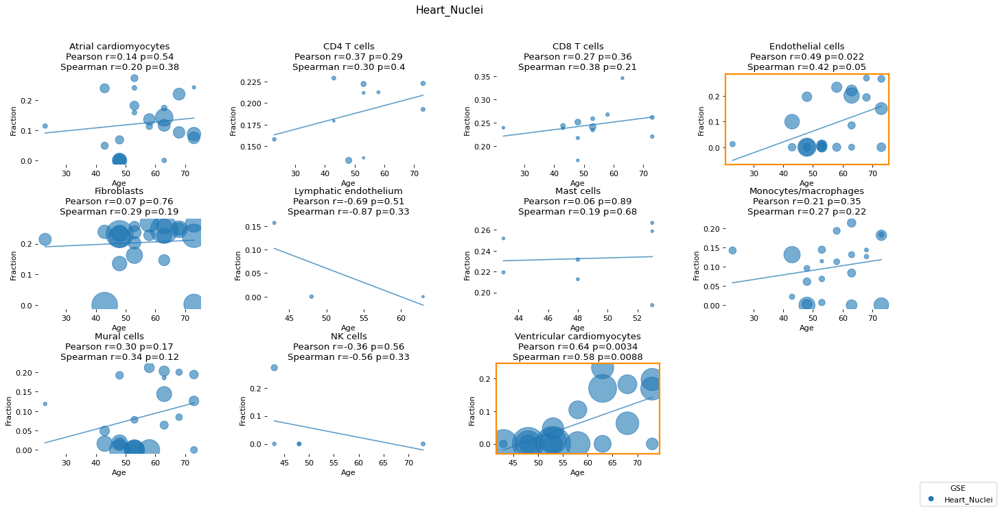

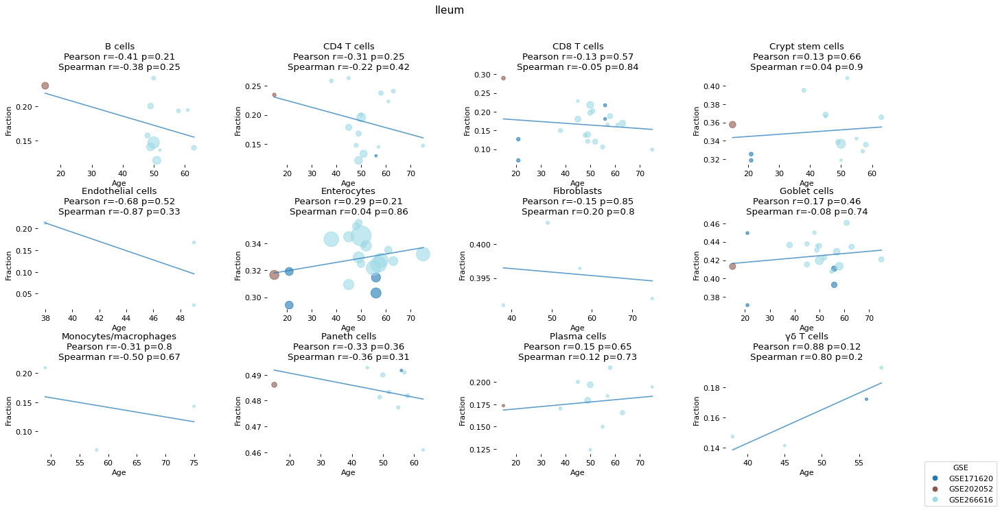

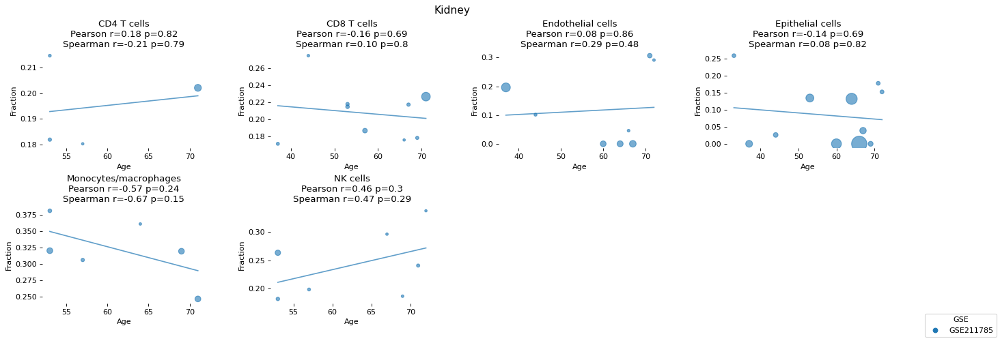

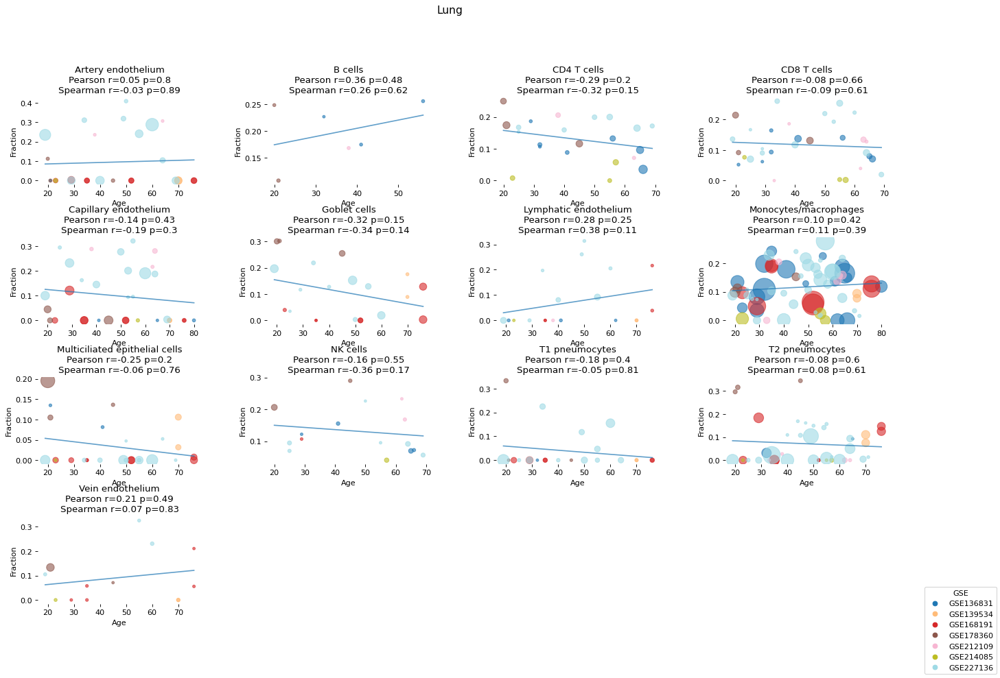

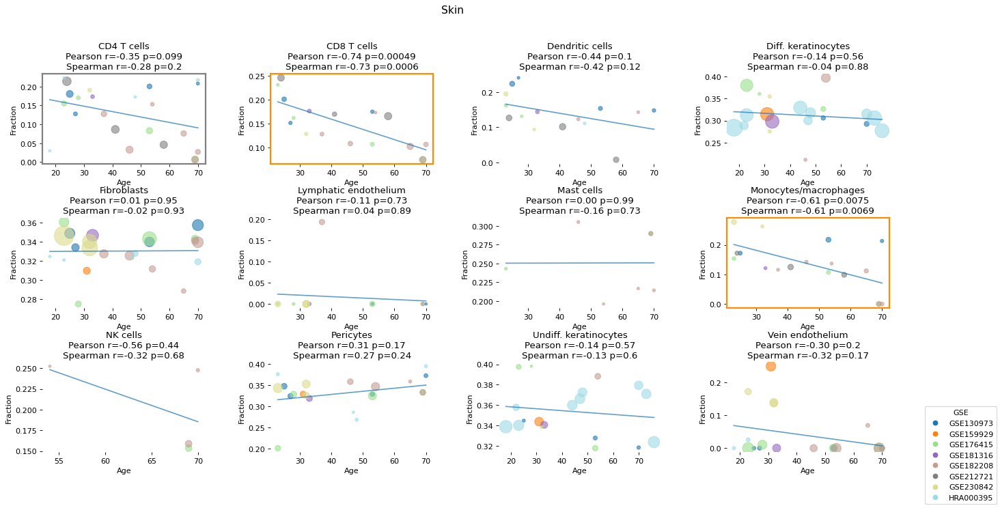

                                          sid_is_sen_median_gse 


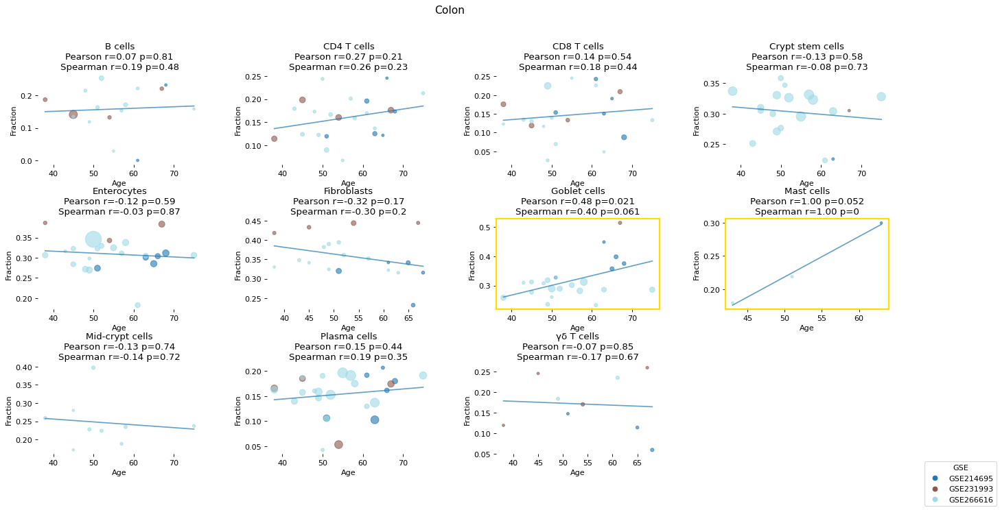

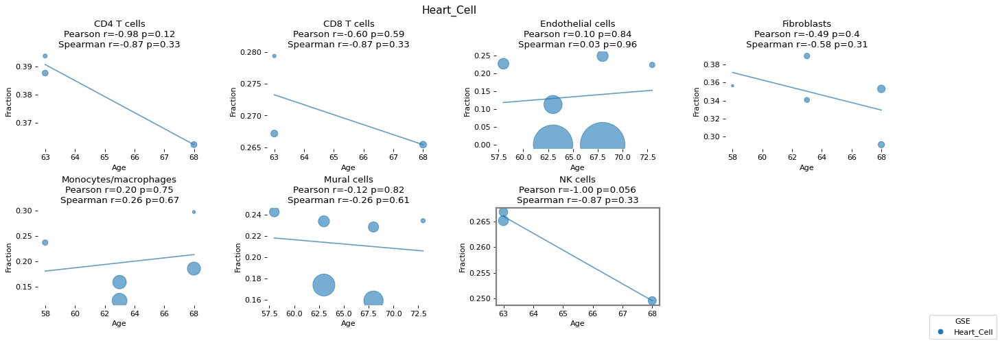

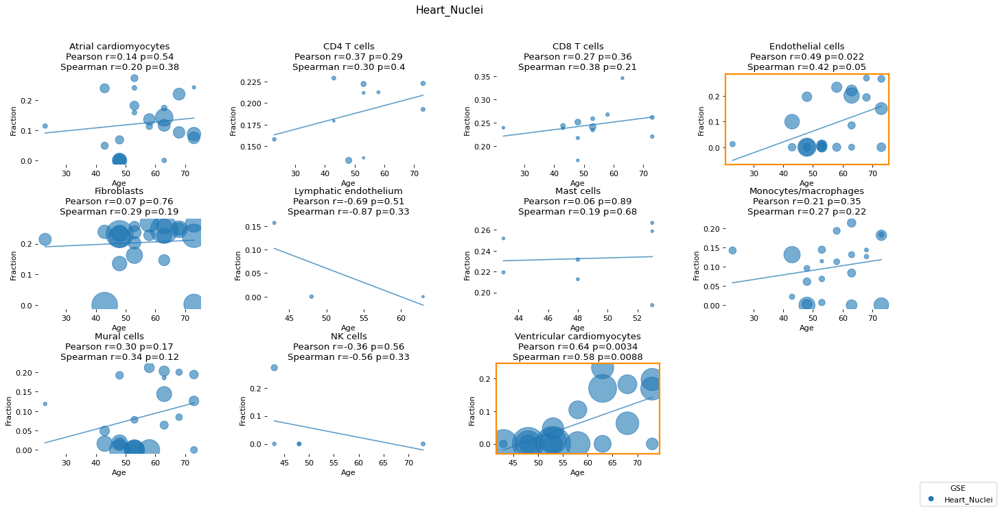

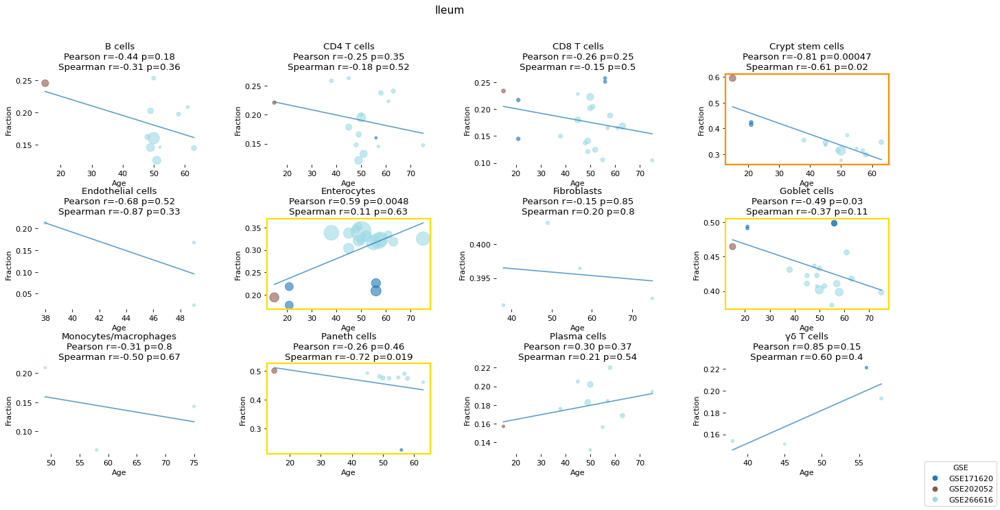

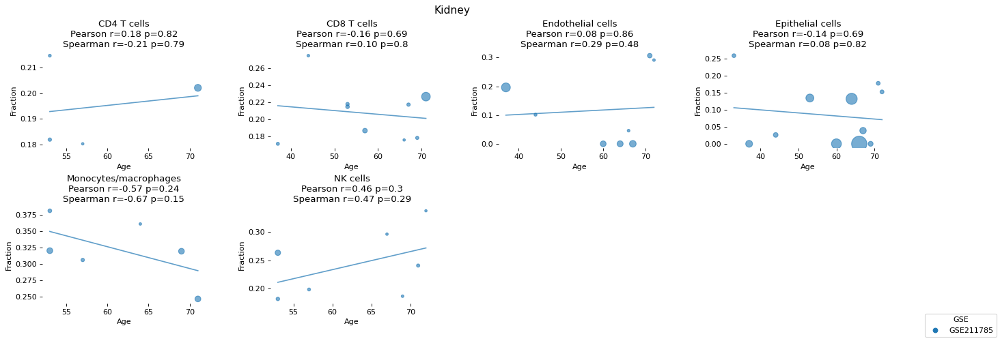

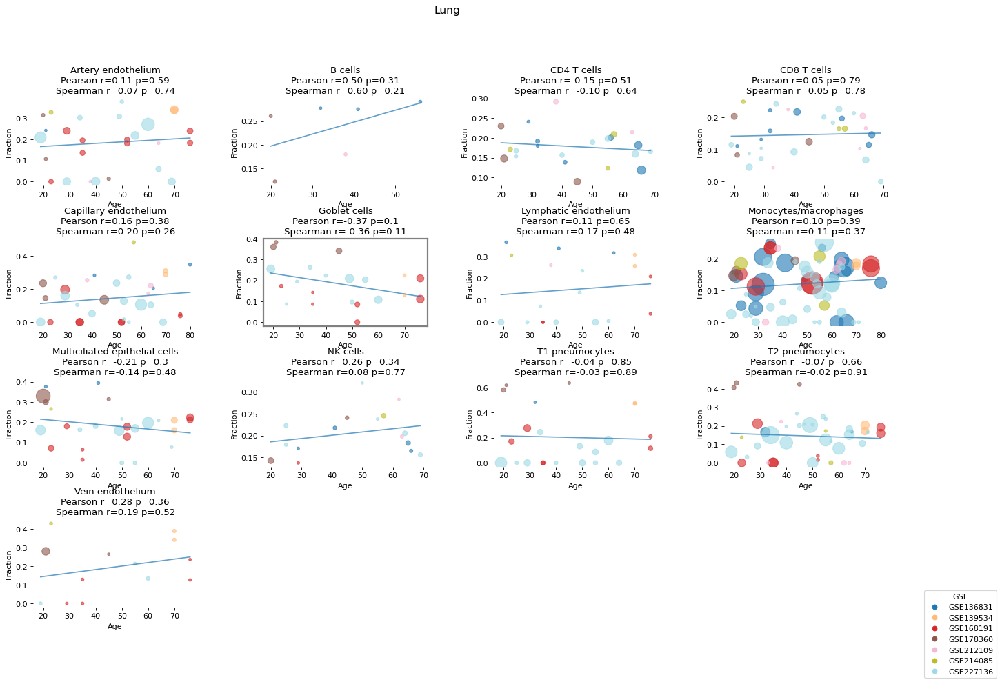

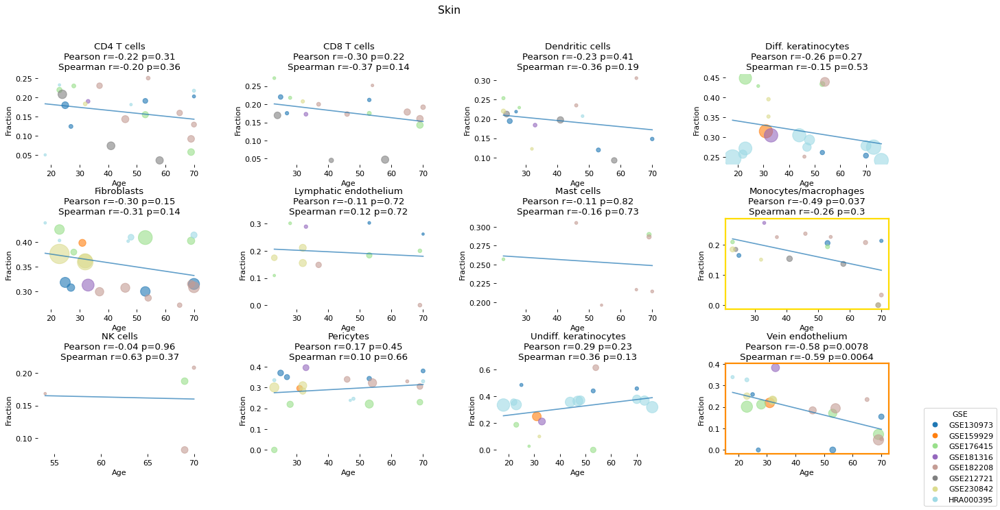

                                          sid_is_sen_median_gsm 


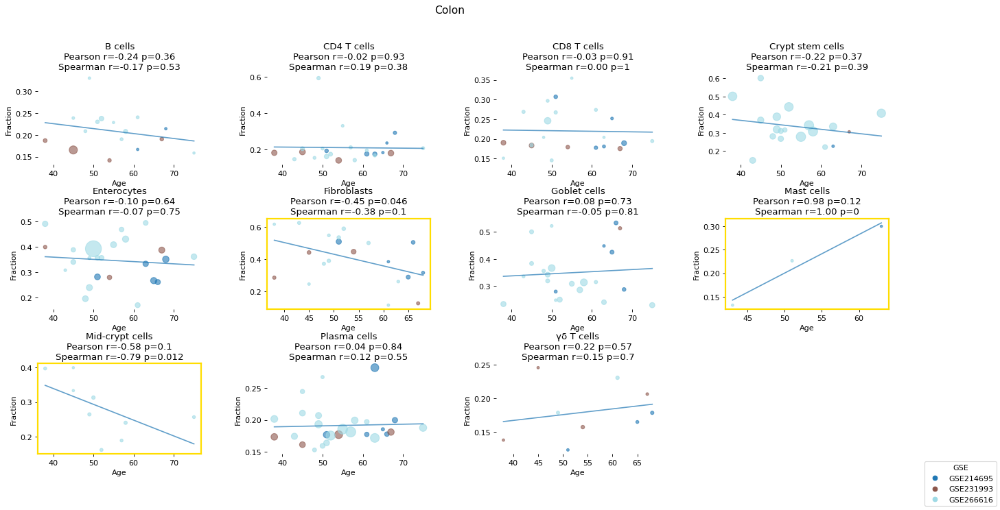

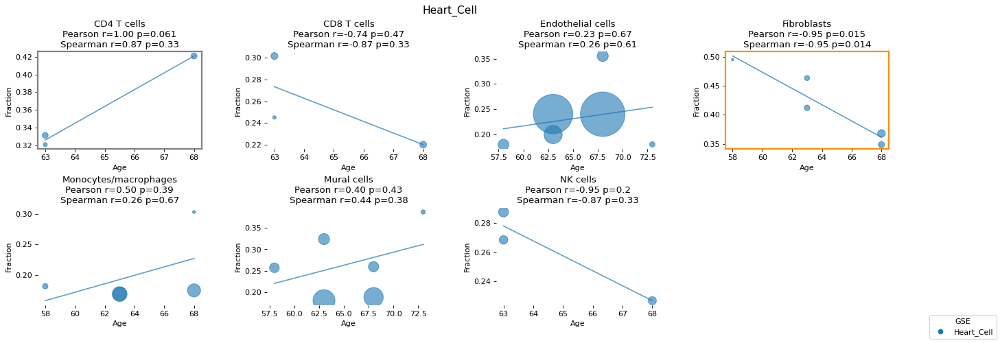

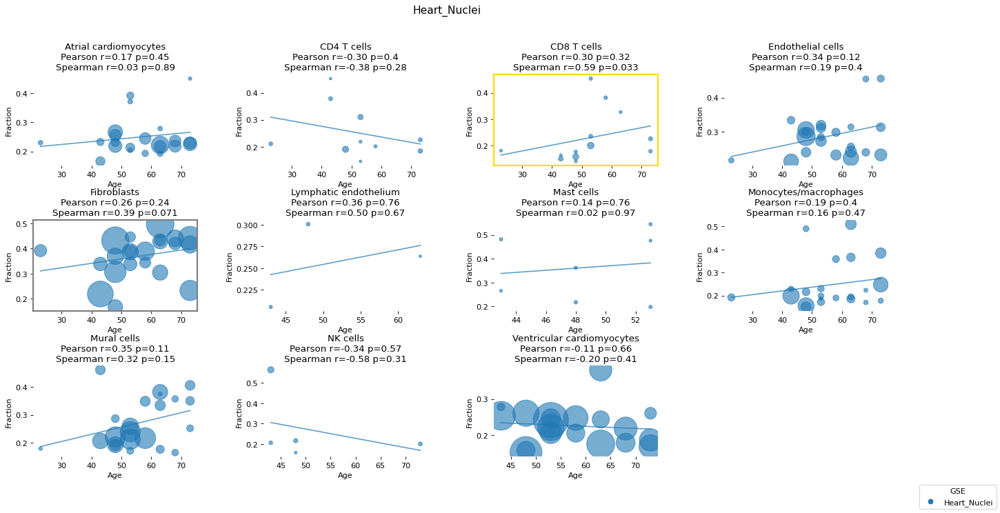

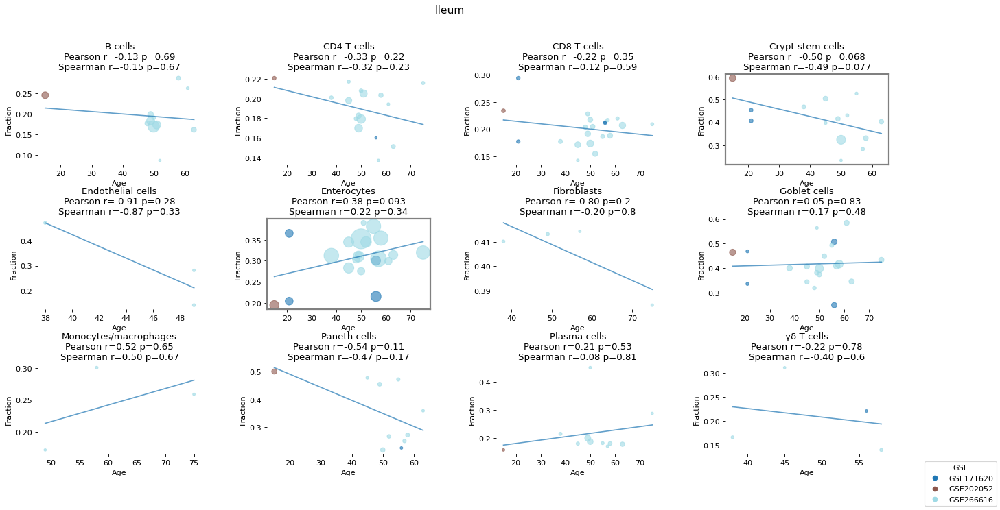

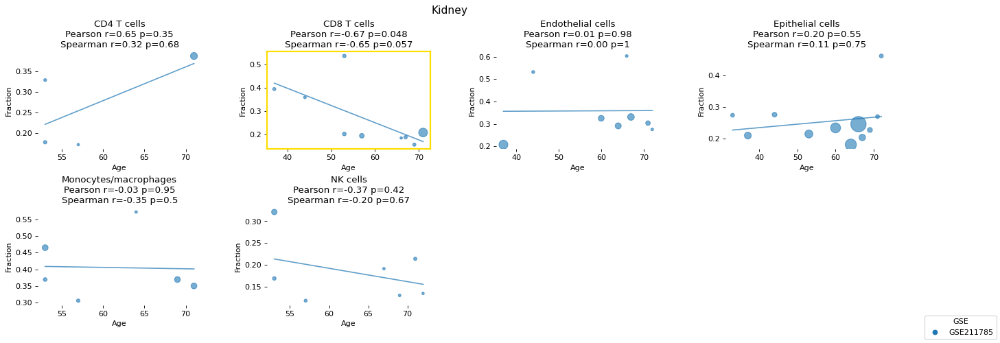

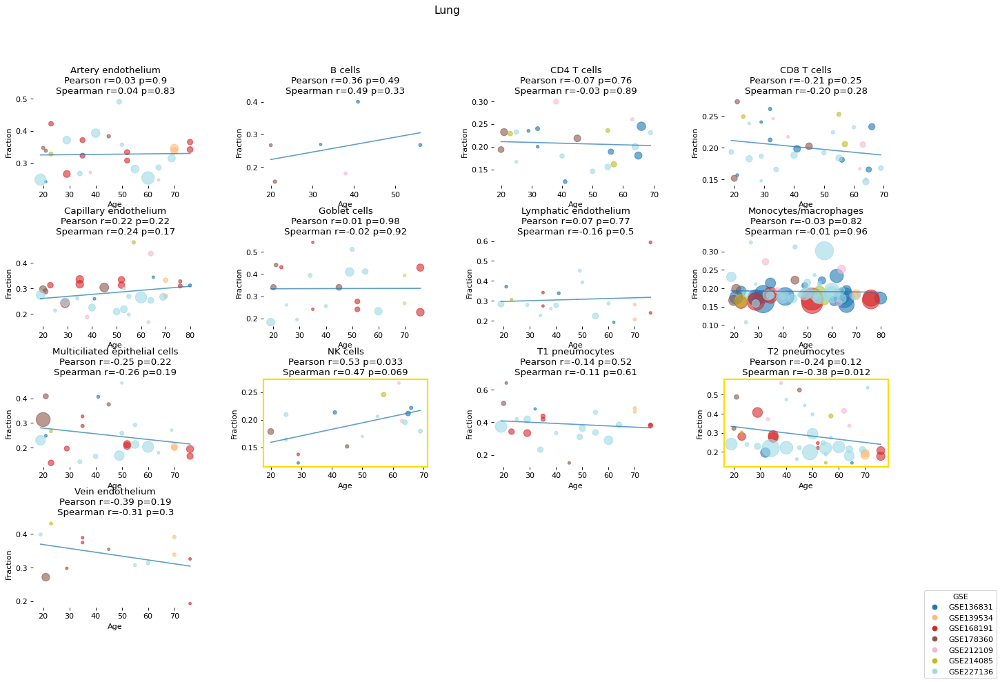

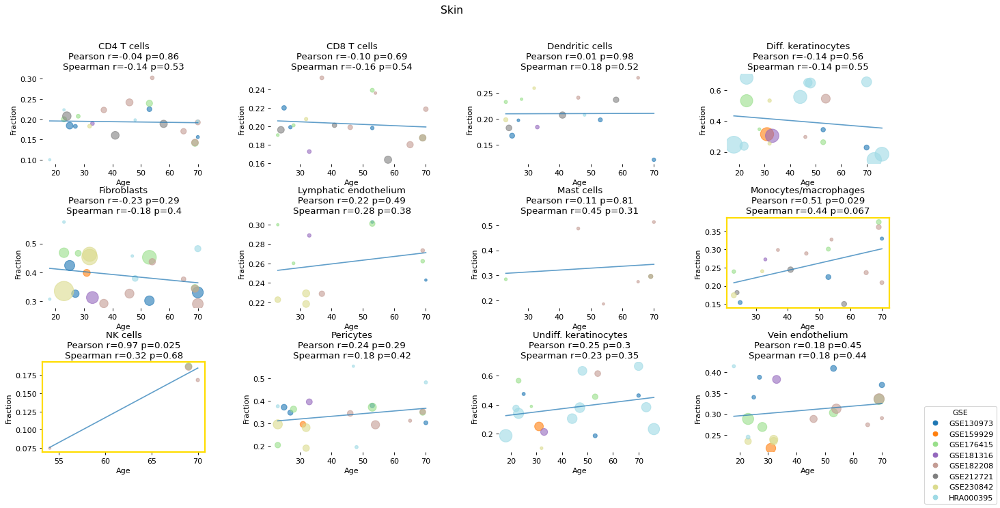

                                          ds_is_sen_median_ct 


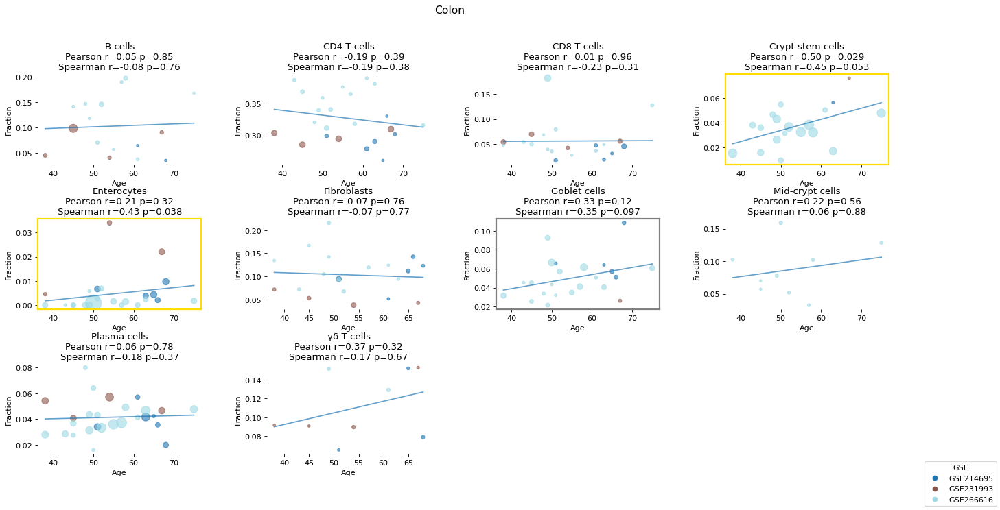

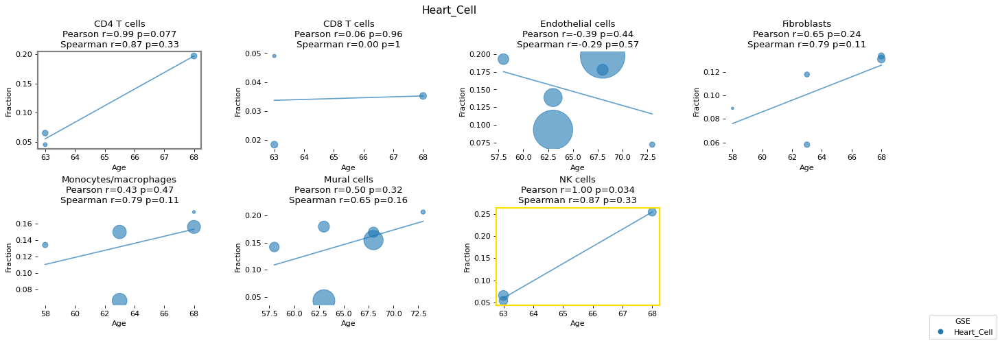

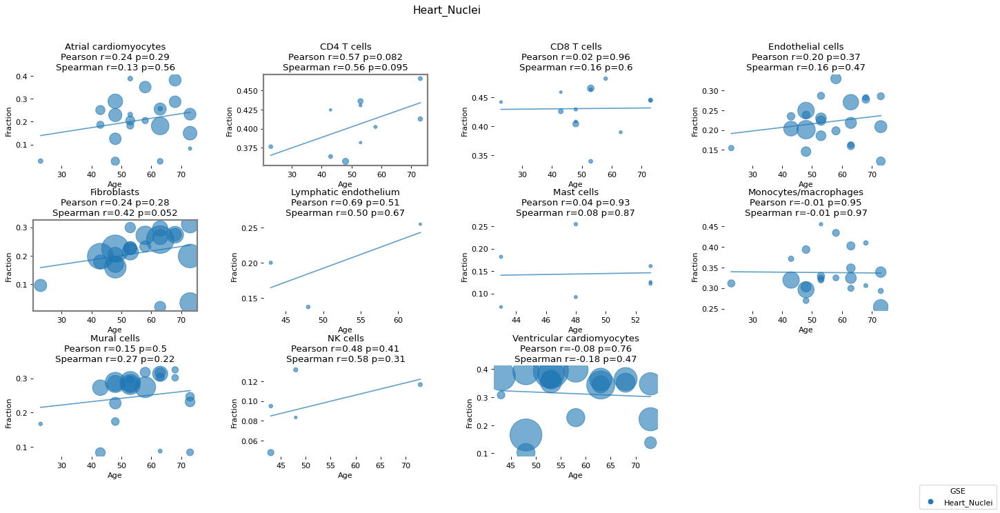

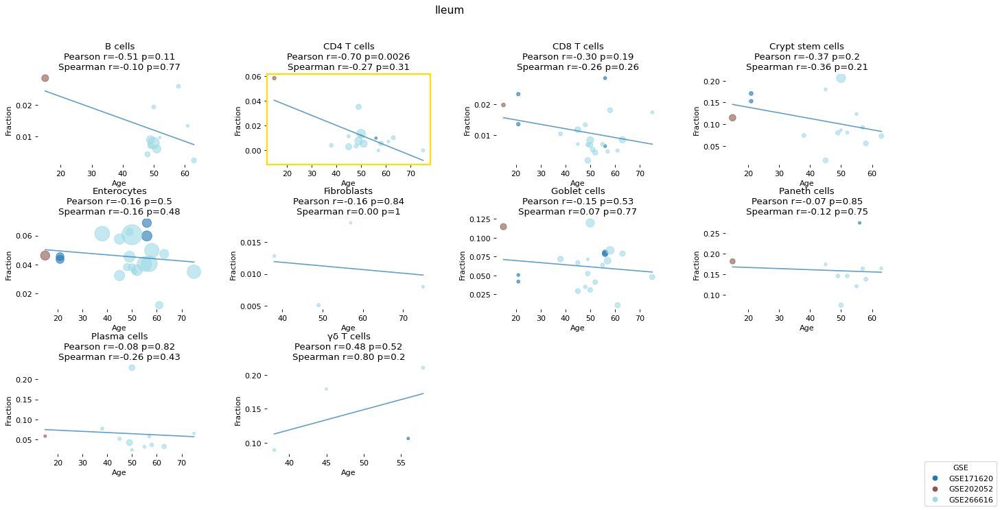

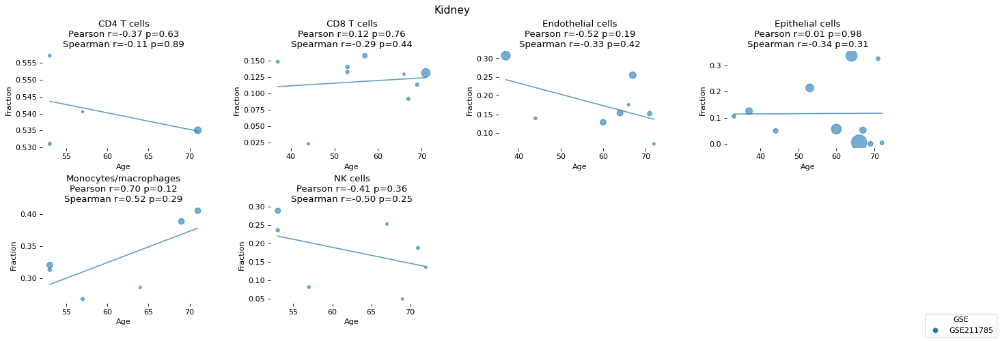

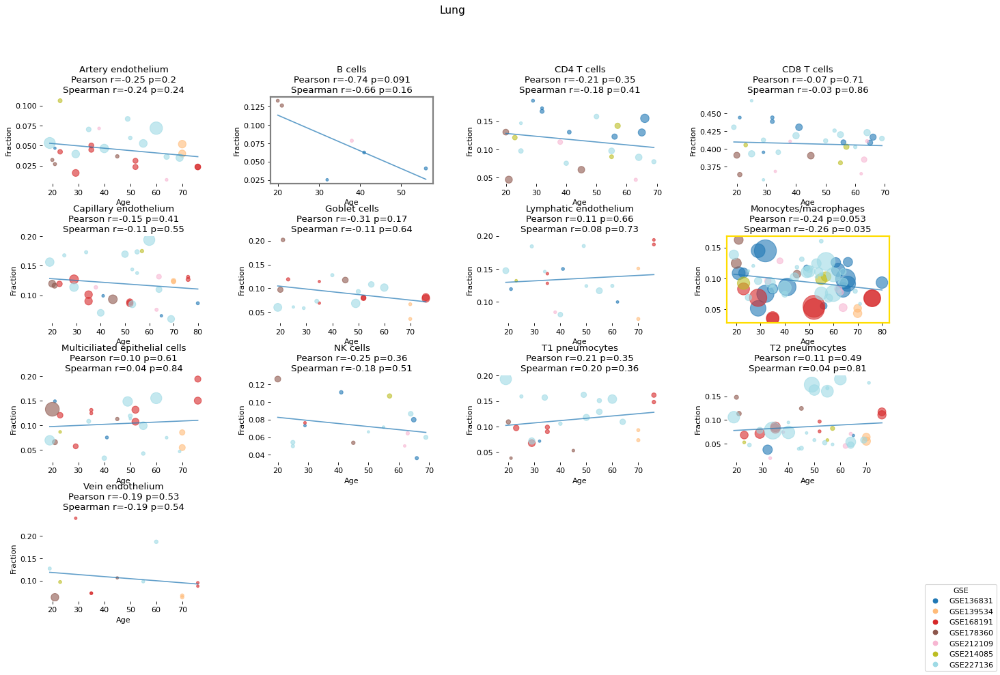

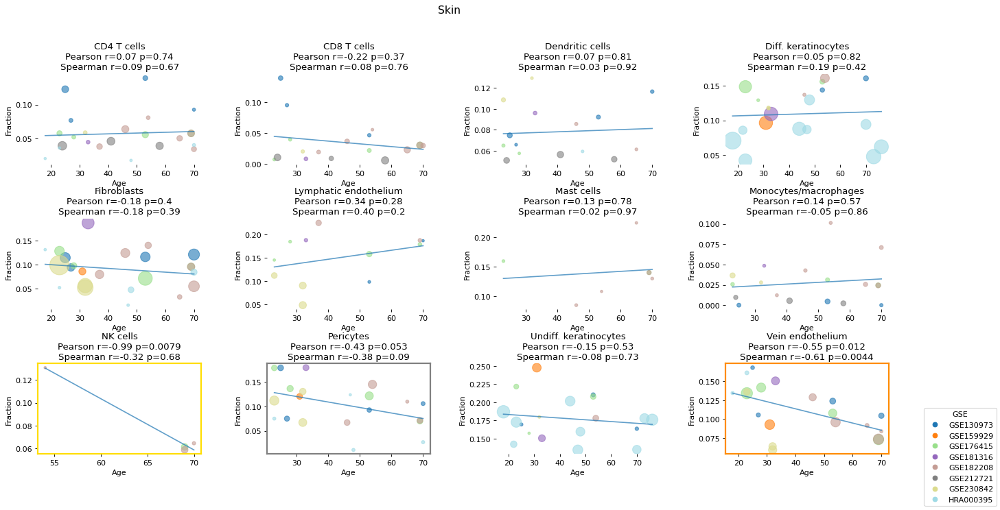

                                          ds_is_sen_median_gse 


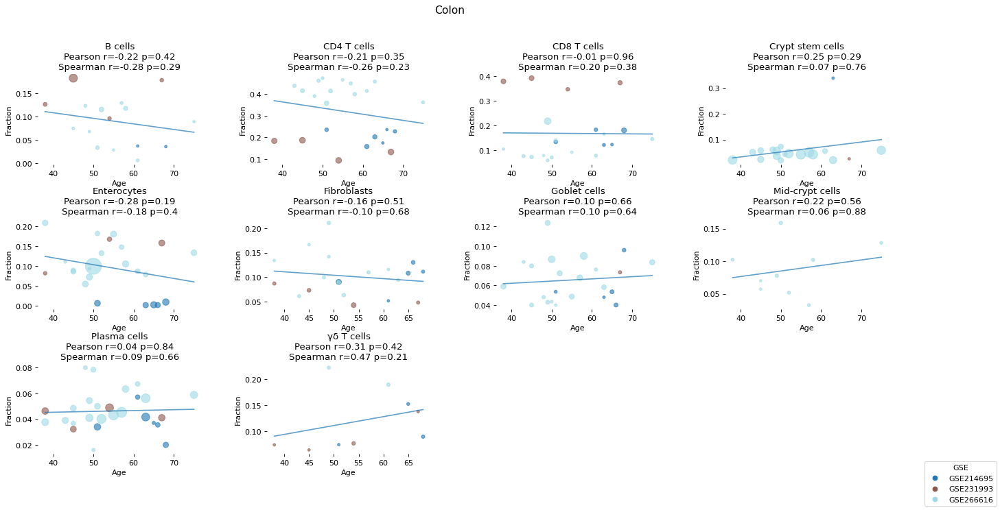

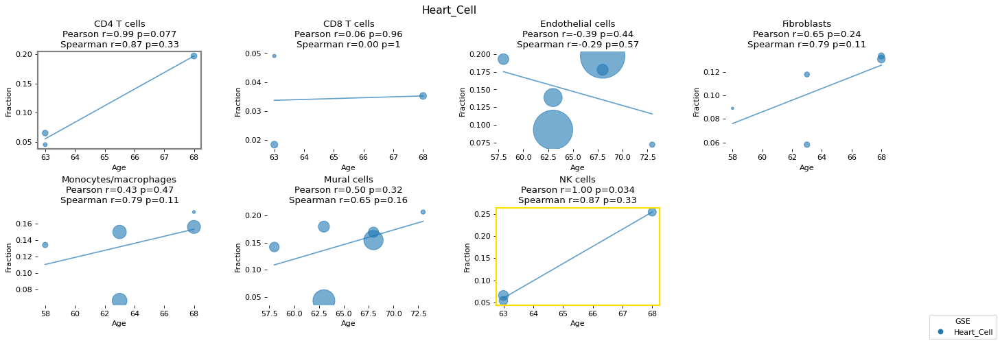

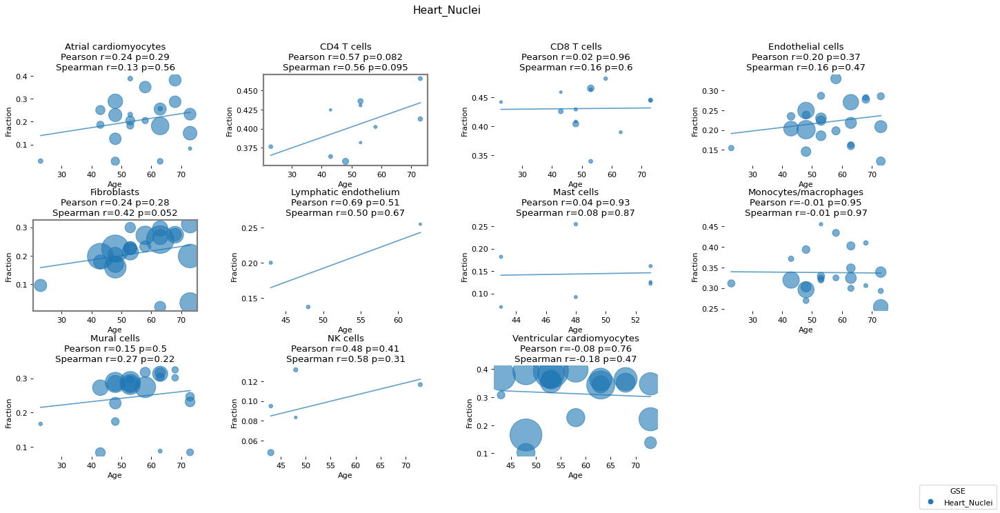

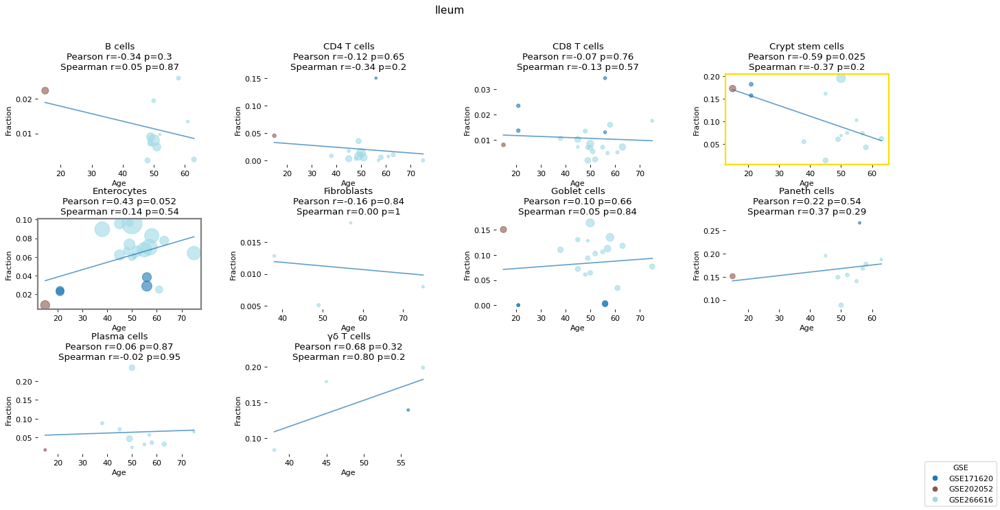

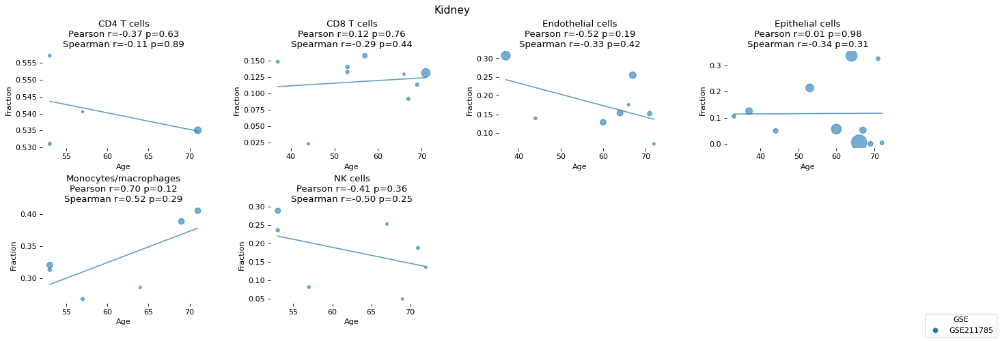

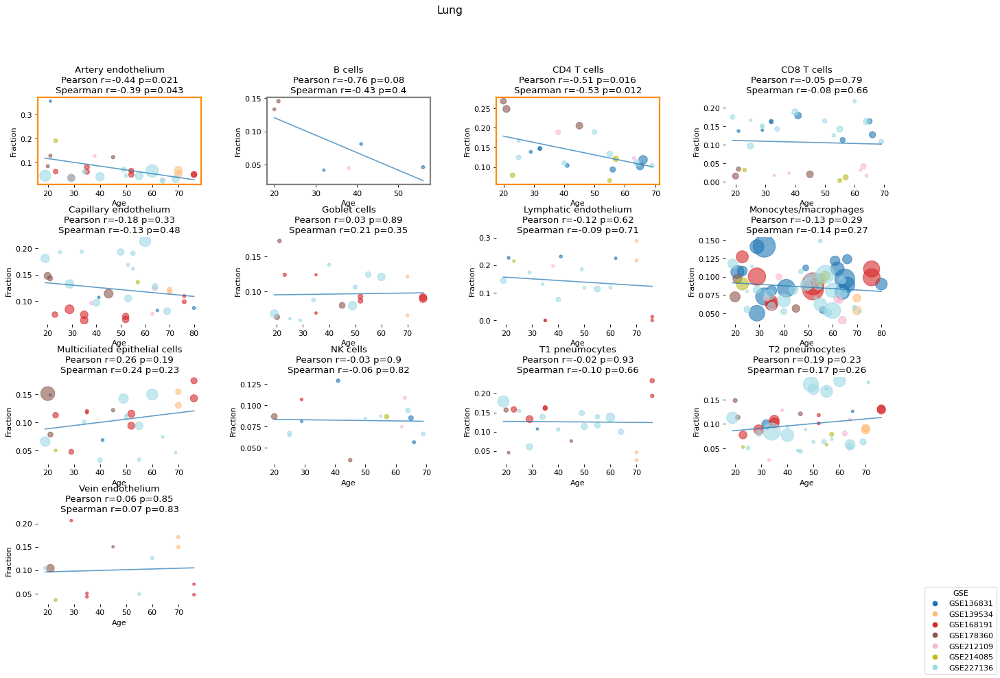

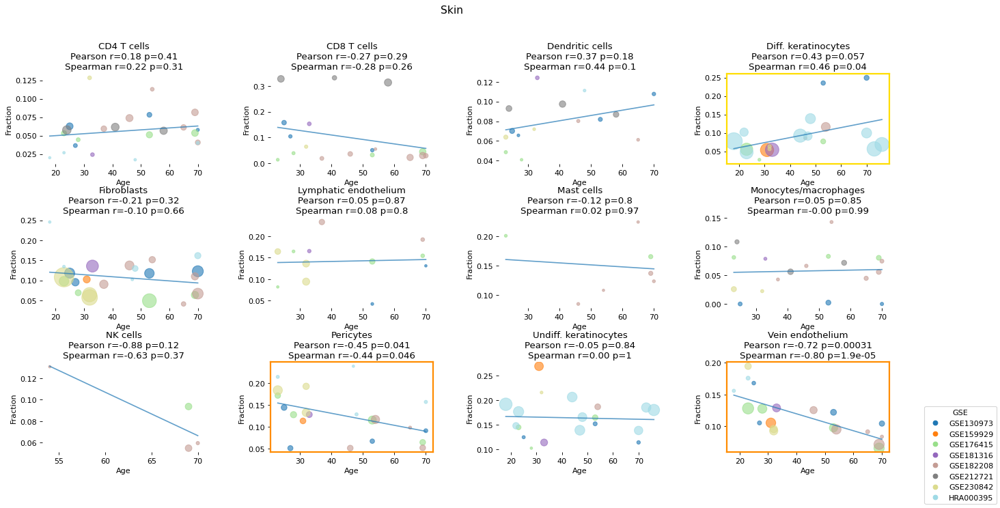

                                          ds_is_sen_median_gsm 


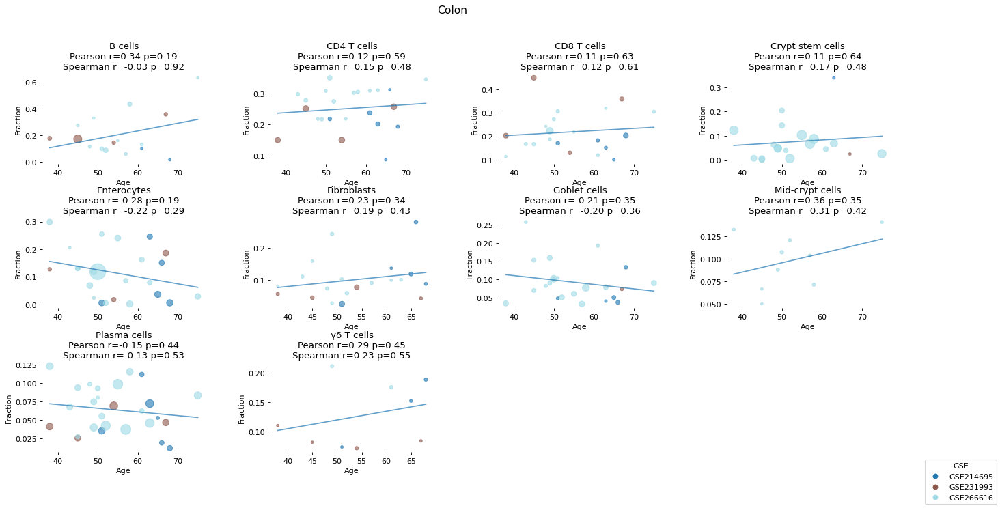

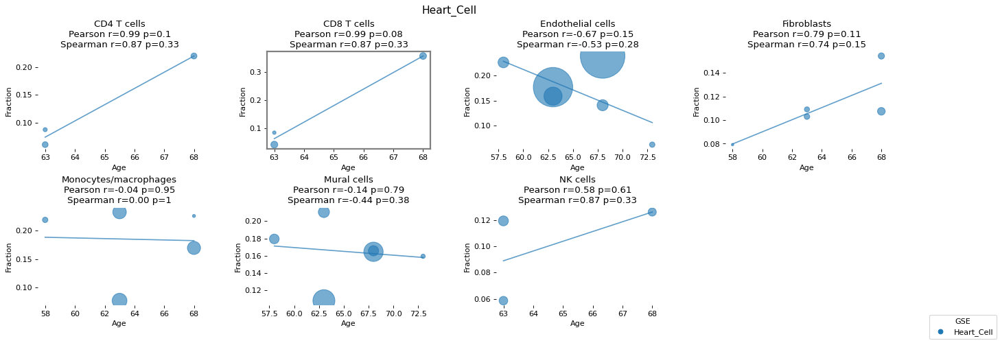

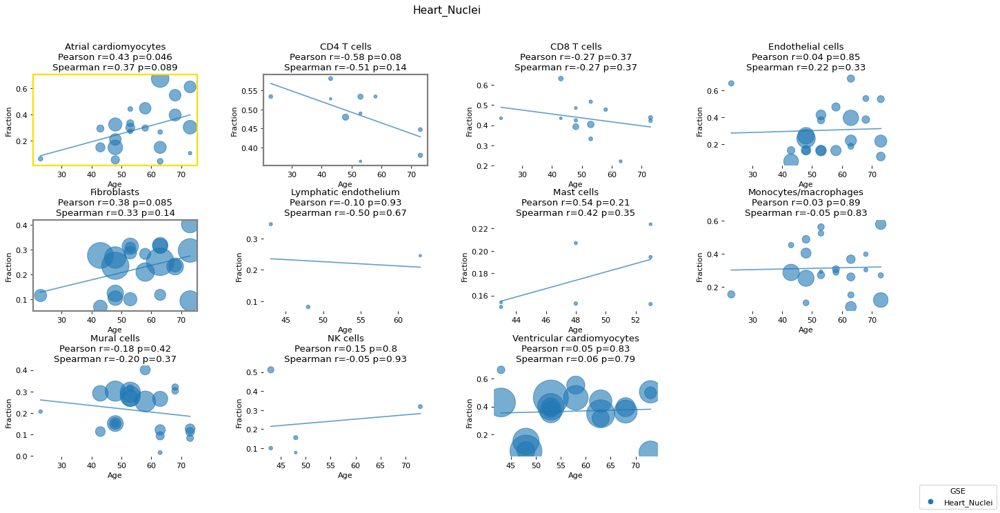

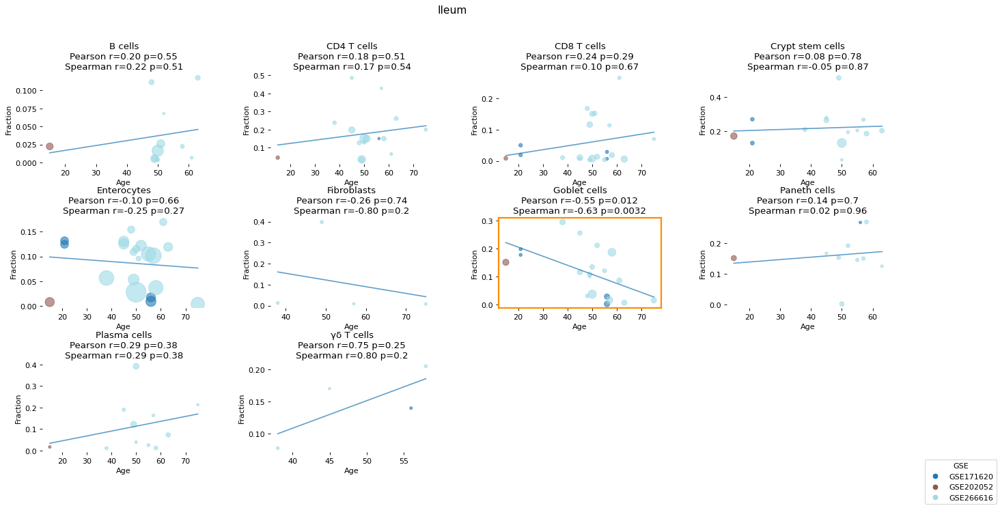

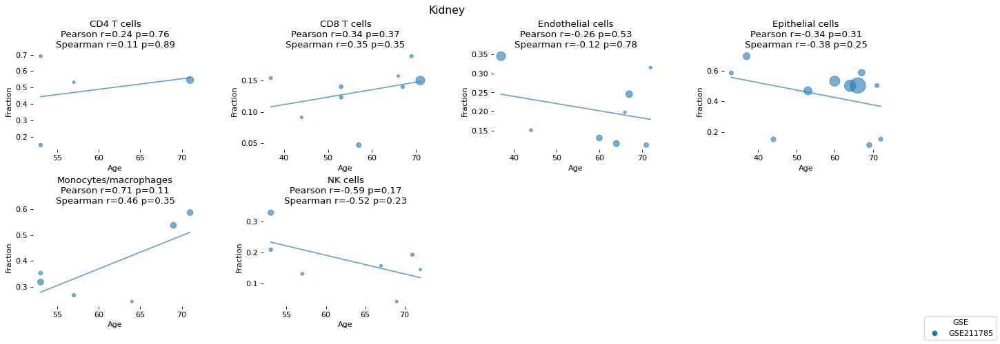

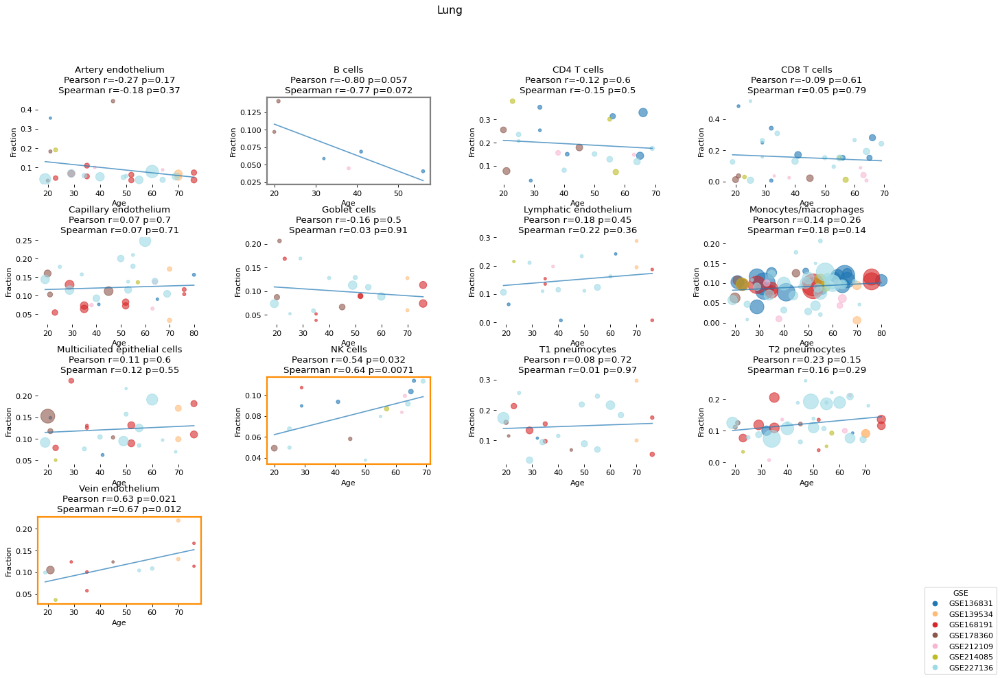

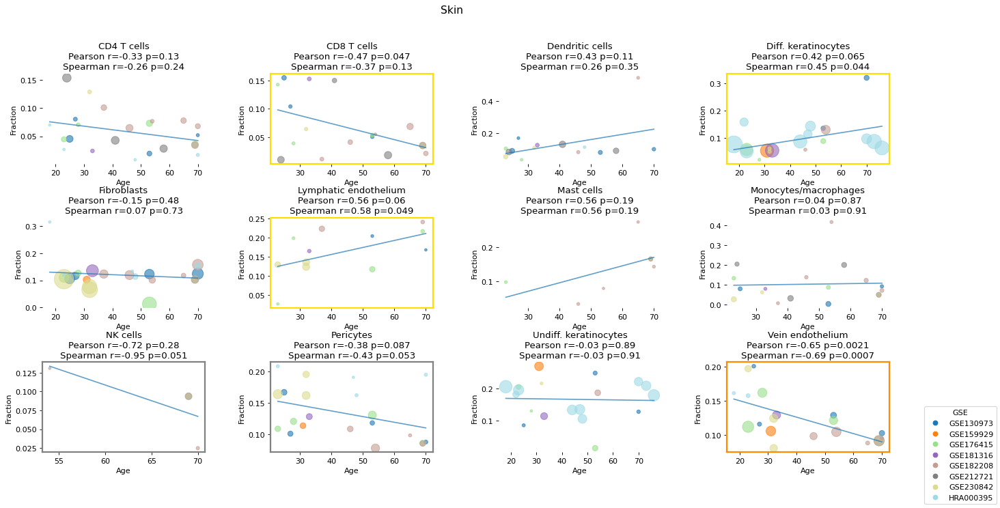

In [35]:
"""
output saved to:
5.1_2_level_corr_dotplots
"""
all_stats = []
for method in ["sp", "sid", "ds"]:
    for level in [
        "ct",
        "gse",
        "gsm",
    ]:
        column = f"{method}_is_sen_median_{level}"
        valid = obs[column].notna()
        obs_filt = obs.loc[valid].copy()

        print("=" * 100, "\n", " " * 40, column, "\n", "=" * 100)
        stats_dict = s7_helpers.count_plot_sen_corrs(obs_filt, column)

        df_stats = pd.DataFrame.from_dict(stats_dict, orient="index")
        df_stats["method"] = method
        df_stats["level"] = level
        df_stats.index = pd.MultiIndex.from_tuples(
            df_stats.index, names=["Tissue_global", "cell_type"]
        )
        df_stats = df_stats.reset_index()
        all_stats.append(df_stats)


In [37]:
print(df_stats.shape)
df_stats.head()

(69, 11)


,Tissue_global,cell_type,pearson_r,pearson_p,spearman_r,spearman_p,n_donors,pearson_fdr,spearman_fdr,method,level
0,Colon,B cells,0.344317,0.191581,-0.026510,0.922367,16,0.531316,0.975331,ds,gsm
1,Colon,CD4 T cells,0.118351,0.590691,0.153599,0.484099,23,0.823513,0.755712,ds,gsm
2,Colon,CD8 T cells,0.110837,0.632439,0.117111,0.613169,21,0.833922,0.829581,ds,gsm
3,Colon,Crypt stem cells,0.114544,0.640549,0.171354,0.483041,19,0.833922,0.755712,ds,gsm
4,Colon,Enterocytes,-0.275656,0.192311,-0.224157,0.292345,24,0.531316,0.662960,ds,gsm


In [43]:
corr_df = pd.concat(all_stats, axis=0)
print(corr_df.shape)
corr_df.head()

(567, 11)


,Tissue_global,cell_type,pearson_r,pearson_p,spearman_r,spearman_p,n_donors,pearson_fdr,spearman_fdr,method,level
0,Colon,B cells,0.526300,0.036238,0.493373,0.052132,16,0.119057,0.217114,sp,ct
1,Colon,CD4 T cells,0.209416,0.337556,0.202820,0.353333,23,0.475815,0.578328,sp,ct
2,Colon,Crypt stem cells,0.036195,0.883049,-0.121266,0.620931,19,0.901837,0.805532,sp,ct
3,Colon,Enterocytes,0.437118,0.032687,0.426116,0.037870,24,0.119057,0.217114,sp,ct
4,Colon,Fibroblasts,0.554372,0.011194,0.623730,0.003295,20,0.094523,0.039545,sp,ct


In [ ]:
corr_df.to_csv(".././5.1_2_level_corr_stats.csv")